# ¿De qué raza es? Identificar 37 razas de perros y gatos con un clasificador cuántico de *data re-uploading*

**Proyecto final de Computación Cuántica · Propuesta A**
Karla Beatriz Rojas Chimal (320048025) y Victor Emiliano Calderón Gutiérrez (423097331)
Prof. Naomi Itzel Reyes Granados · Ayud. Sebastián González Juárez · Entrega: 7 de diciembre de 2026

| | |
|---|---|
| **Datos** | Oxford-IIIT Pet (7 349 fotos, 37 razas: 12 de gatos y 25 de perros) |
| **Pipeline clásico** | ResNet-50 congelada → estandarización → PCA o LDA → ángulos en $[0,\pi]$ |
| **Modelos cuánticos** | circuito plano de 6 qubits y circuito jerárquico (especie → raza) de 4–5 qubits, ambos con *data re-uploading* |
| **Herramientas** | PennyLane (modelo y gradientes), Qiskit (verificación cruzada y costo), scikit-learn, PyTorch |
| **Entorno** | `compu_cuantica` (Python 3.11, PennyLane 0.45, Qiskit 2.6, PyTorch 2.6) |

## 0. El problema

Cuando un refugio recibe un animal sin papeles, alguien tiene que escribir en la ficha de qué raza parece. Se hace a ojo, de prisa y con la jaula todavía abierta. Ese dato no es un adorno: de la raza se infiere el tamaño que tendrá de adulto y cuánto ejercicio necesita, qué problemas hereditarios conviene vigilar (displasia de cadera en razas grandes, problemas respiratorios en las de hocico chato), si aplica algún reglamento local y qué le van a buscar los adoptantes en el filtro de la página. Y casi siempre se registra mal o se deja en blanco.

Lo que queremos es lo que cualquier refugio ya tiene a la mano: **la foto que se toma al ingreso**. A partir de ella, sugerir una de 37 razas. No pretendemos reemplazar a una persona con experiencia, solo darle una primera propuesta que pueda corregir.

La pregunta que guía el proyecto es esta:

> *¿Puede un clasificador variacional cuántico de pocos qubits identificar 37 razas con un desempeño comparable al de modelos clásicos de capacidad parecida? Y como 37 clases no caben cómodamente en la lectura de un circuito pequeño, ¿ayuda partir el problema en dos pasos, primero la especie y luego la raza?*

### Por qué este problema y no uno más sencillo

Nuestra propuesta anterior era perros contra gatos. Nos señalaron, con razón, que ya está resuelto con un extractor convolucional congelado y un circuito de 4 qubits (Martín-Pérez *et al.*, 2026, más de 97.5 % de *accuracy*) y que una tarea binaria es poca cosa frente a las opciones del curso. Con 37 razas el problema cambia de naturaleza:

| | Opción 1 (Dry Bean) | Este proyecto (Oxford-IIIT Pet) |
|---|---|---|
| Clases | 7 | **37** |
| Ejemplos de entrenamiento por clase | ≈ 1 350 | ≈ 100 |
| Entrada | 16 medidas ya calculadas | fotos RGB con pose, fondo e iluminación distintos |
| Parecido entre clases | variedades bastante separables | **grano fino**: un *American Pit Bull Terrier* y un *Staffordshire Bull Terrier* se confunden hasta a simple vista |
| Azar | 14.3 % | 2.7 % |
| Qubits para leer las clases | 3 | 6 (o arquitectura jerárquica) |

Del lado cuántico, el trabajo más cercano que encontramos es el de Yamaoka, Chan y Mitarai (2026), que compara clasificadores variacionales cuánticos con clásicos sobre características de extractores congelados en diez conjuntos de imágenes, entre ellos este. Por el costo de simular, usan solo **las primeras cuatro clases** de cada conjunto, y ellos mismos señalan que falta probar con más clases y con los conjuntos completos. Aquí usamos las 37 y probamos una arquitectura jerárquica que ese trabajo no explora.

## 1. Marco teórico

### 1.1 Formalización

Tenemos un conjunto $\mathcal{D}=\{(\mathbf{I}_i,y_i)\}_{i=1}^{N}$ de fotografías con etiqueta de raza $y_i\in\{0,\dots,36\}$. La especie $e(y)\in\{\text{gato},\text{perro}\}$ queda determinada por la raza. Fijamos un extractor congelado $g:\mathbf{I}\mapsto\mathbb{R}^{2048}$ y una reducción $\pi:\mathbb{R}^{2048}\to\mathbb{R}^{d}$ con $d\in\{8,12,16\}$, de modo que $\mathbf{x}_i=\pi(g(\mathbf{I}_i))$. Buscamos un clasificador $f_{\boldsymbol\theta}:\mathbb{R}^{d}\to\Delta^{36}$ (símplex de probabilidades sobre las 37 razas) que minimice la entropía cruzada multiclase:

$$
\mathcal{L}(\boldsymbol\theta)=-\frac1N\sum_{i=1}^{N}\log\big[f_{\boldsymbol\theta}(\mathbf{x}_i)\big]_{y_i},
\qquad
\hat y(\mathbf{x})=\arg\max_k\,[f_{\boldsymbol\theta}(\mathbf{x})]_k .
$$

Como $\boldsymbol\theta$ son ángulos de rotación, $\mathcal{L}$ **no es convexa**: el resultado depende del punto de partida, así que cada experimento importante se repite con tres semillas.

En la versión jerárquica la probabilidad se factoriza con la regla de la cadena,

$$
P(y\mid\mathbf{x})=P\big(e(y)\mid\mathbf{x}\big)\;P\big(y\mid e(y),\mathbf{x}\big),
$$

con un circuito para la especie y uno por especie para la raza.

**Métricas.** *Accuracy* top-1 y top-5 (con 37 clases parecidas, acertar entre las cinco primeras sugerencias también sirve en la práctica), F1 macro, matriz de confusión y, por la jerarquía, *accuracy* a nivel especie y qué parte de los errores ocurre entre razas de la misma especie.

### 1.2 Cómo se resuelve de forma clásica

| Familia | Ejemplos | Comentario |
|---|---|---|
| Rasgos hechos a mano | forma + apariencia, SVM | El artículo original del conjunto (Parkhi *et al.*, 2012) reporta alrededor de 59 % en las 37 razas. |
| Transferencia con extractor congelado | CNN preentrenada + regresión logística / SVM / MLP | Es el estándar práctico y el que usamos. Las características de ImageNet ya separan muy bien las razas. |
| *Fine-tuning* de toda la red | ResNet, ViT | El mejor desempeño, pero requiere reentrenar millones de parámetros. |
| Basados en distancia | centroides, *k*-NN | Referencia geométrica; el análogo clásico del *swap test*. |

Nosotros nos quedamos con la segunda fila: el extractor se calcula una sola vez y todo lo que viene después (clásico o cuántico) trabaja sobre los mismos vectores. Así la comparación mide el efecto del **clasificador final** y no el de la red convolucional.

### 1.3 Algoritmo cuántico: *data re-uploading*

Un modelo variacional que codifica el dato una sola vez al inicio produce, como función de $\mathbf{x}$, una serie de Fourier cuyas frecuencias dependen solo de esa codificación (Schuld, Sweke y Meyer, 2021). Con compuertas $e^{-ixH/2}$ tenemos únicamente las frecuencias $\{-1,0,1\}$ por variable, y eso alcanza para fronteras muy suaves y para poco más. La idea de Pérez-Salinas *et al.* (2020) es **volver a subir el dato** entre bloques entrenables:

$$
U_{\boldsymbol\theta}(\mathbf{x})=\prod_{l=L}^{1}W_l(\boldsymbol\theta_l)\,S_l(\mathbf{x};\boldsymbol\alpha_l),
\qquad |\psi(\mathbf{x})\rangle=U_{\boldsymbol\theta}(\mathbf{x})|0\rangle^{\otimes n}.
$$

Cada capa $l$ tiene dos partes:

* **Codificación** $S_l$. Con $d$ variables y $n$ qubits, repartimos las variables entre los qubits (la variable $j$ va al qubit $j \bmod n$). Cada una entra como el ángulo de una rotación $R_Y(\alpha\,x_j)$ o $R_Z(\alpha\,x_j)$, alternando, con un factor de escala $\alpha$ entrenable que cumple el papel del peso de una neurona. Con $d=2n$ cada qubit recibe dos variables por capa y no se tira información.
* **Bloque entrenable** $W_l$. Una rotación general $\mathrm{Rot}(\phi,\vartheta,\omega)=R_Z(\omega)R_Y(\vartheta)R_Z(\phi)$ en cada qubit, seguida de un anillo de CNOT que los entrelaza.

Es la misma estructura de los circuitos que vimos en el Lab 7 (*feature map* + *ansatz* de rotaciones y CNOT), con dos cambios: el mapa de características se repite en cada capa, y sus ángulos se multiplican por pesos que también se entrenan.

**Lectura multiclase.** Medimos los qubits en la base computacional. Asignamos a la raza $c$ el estado base $|c\rangle$ y convertimos las probabilidades en una distribución sobre clases con un *softmax* de temperatura entrenable $\beta$:

$$
p_c(\mathbf{x})=\big|\langle c|\psi(\mathbf{x})\rangle\big|^2,\qquad
\big[f_{\boldsymbol\theta}(\mathbf{x})\big]_c=\frac{\exp\big(\beta\,p_c(\mathbf{x})\big)}{\sum_{c'}\exp\big(\beta\,p_{c'}(\mathbf{x})\big)} .
$$

La temperatura no es un lujo. Cuando hay 37 clases, cada $p_c$ es chica y sin $\beta$ el *softmax* quedaría casi uniforme. Con $n=6$ hay $2^6=64$ estados, así que los 27 sobrantes funcionan como desagüe de probabilidad. En el Lab 7 se probaron tres formas de leer el circuito (probabilidades agrupadas, valores esperados de Pauli $Z$ con una transformación clásica, y fidelidad con estados objetivo). Usamos la primera como lectura principal y comparamos con la segunda en las ablaciones.

**¿Por qué este algoritmo puede resolver el problema?**

1. *Expresividad.* Cada re-subida añade frecuencias al modelo de Fourier del circuito, así que las fronteras entre 37 regiones del espacio de características pueden ser no lineales.
2. *Entrelazamiento.* Los CNOT acoplan variables que entraron por qubits distintos, algo parecido a lo que hacen las capas ocultas de una red clásica.
3. *Pocos parámetros por clase.* Un clasificador lineal sobre 12 variables y 37 clases necesita $12\cdot37+37=481$ parámetros. El circuito plano de 6 qubits y 5 capas tiene 151 (con $d=12$), porque la lectura sobre $2^n$ estados base da muchas salidas sin una matriz de pesos grande. Si esa economía alcanza para clasificar bien es justo lo que medimos.
4. *Universalidad con asterisco.* Con suficientes capas la familia aproxima funciones acotadas (Pérez-Salinas *et al.*), pero eso no garantiza que el optimizador encuentre buenos parámetros. La evidencia sale de los experimentos, no de este argumento.

### 1.4 La variante jerárquica

Si un circuito de 6 qubits tiene que repartir 37 razas entre 64 estados, cada raza ocupa un rincón diminuto de la distribución. La alternativa es copiar cómo lo haría una persona: primero decidir si es perro o gato, y después elegir entre las razas de esa especie.

* **Especie:** 4 qubits, lectura binaria (la probabilidad de $|1\rangle$ en el primer qubit).
* **Raza de gato:** 4 qubits ($2^4=16\ge12$ estados), entrenado solo con gatos.
* **Raza de perro:** 5 qubits ($2^5=32\ge25$ estados), entrenado solo con perros.

Ningún circuito pasa de 5 qubits, así que cada uno es más chico y menos profundo. El precio es que un error en la especie se arrastra a la raza, por lo que más adelante medimos de dónde viene cada error.

### 1.5 ¿Para qué usar cómputo cuántico aquí?

Con honestidad: no esperamos ventaja. Un circuito de 6 qubits vive en un espacio de 64 dimensiones y se simula sin esfuerzo en una laptop, y para estos datos un MLP o una SVM clásica ya hacen un buen trabajo. Lo que sí podemos preguntarnos es si un modelo cuántico **muy pequeño** compite con modelos clásicos de tamaño parecido, cuánto cuesta en mediciones y profundidad, y qué pasa cuando hay muchas clases y pocos ejemplos por clase, que es el régimen donde la propuesta de Yamaoka *et al.* dice que falta evidencia. Un resultado negativo también cuenta, y lo vamos a discutir como tal.

## 2. Entorno y librerías

| Librería | Para qué la usamos | Por qué |
|---|---|---|
| `torch`, `torchvision` | descarga del conjunto, transformaciones de imagen y ResNet-50 preentrenada | Reimplementar una CNN no aporta al objetivo del curso. |
| **`pennylane`** | definir el circuito y derivarlo | Con *parameter broadcasting* se evalúa un minibatch completo en una sola pasada y el entrenamiento tarda minutos y no horas. |
| `qiskit` | reconstruir el circuito por separado y transpilarlo | Sirve para comprobar que el circuito está bien definido y para medir profundidad y CNOT en compuertas nativas. |
| `scikit-learn` | partición estratificada, estandarización, PCA, LDA, baselines y métricas | Piezas ya probadas; garantiza una comparación justa. |
| `numpy`, `pandas`, `matplotlib` | datos, tablas y figuras | Estándar. |

In [1]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import pennylane as qml
from pennylane import numpy as pnp

import torch, torchvision
from torchvision import transforms as T

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neighbors import NearestCentroid, KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV

import qiskit
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
np.random.seed(SEED)

# Colores que usamos en todas las figuras: gato / perro / modelos cuánticos / clásicos
C_GATO, C_PERRO, C_QNN, C_CLAS = "#e07a5f", "#3d5a80", "#6a4c93", "#8d99ae"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})

# Ponlo en True si solo quieres comprobar que todo corre (pocas épocas, pocas semillas)
MODO_RAPIDO = False

print(f"PennyLane {qml.__version__} | Qiskit {qiskit.__version__} | PyTorch {torch.__version__} | modo rápido: {MODO_RAPIDO}")

PennyLane 0.45.1 | Qiskit 2.6.0 | PyTorch 2.6.0+cu124 | modo rápido: False


## 3. Datos

Oxford-IIIT Pet (Parkhi *et al.*, 2012) tiene 7 349 fotografías de 37 razas, con unas 200 por raza. Hay escalas, poses e iluminaciones de todo tipo, y en muchas fotos aparecen personas, correas o muebles. Se distribuye con licencia CC BY-SA 4.0 y `torchvision` lo descarga directamente.

Respetamos la partición oficial: `trainval` (3 680 imágenes) para entrenar y `test` (3 669) para evaluar, unas 100 por raza en cada una. Del `trainval` apartamos 15 % estratificado por raza como **validación**, que usamos para elegir la mejor época y para decidir entre PCA y LDA. El conjunto de prueba se toca una sola vez, al final.

### 3.1 Extracción de características

Cada foto se redimensiona a 256 px por el lado corto, se recorta al centro a $224\times224$ y se normaliza con la media y la desviación de ImageNet. Esas transformaciones no dependen de nuestros datos, así que no hay fuga de información. La ResNet-50 (pesos de ImageNet, sin reentrenar) nos entrega, tras el *pooling* global, un vector de 2 048 números por foto. Se calcula una sola vez y se guarda en `data/features.npz`; si el archivo ya existe, la celda no hace nada.

In [2]:
DATA = "data"
FEATS = os.path.join(DATA, "features.npz")

def extraer_caracteristicas():
    """Pasa todas las fotos por la ResNet-50 congelada y guarda los vectores de 2048 dimensiones."""
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    net = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V2)
    net.fc = torch.nn.Identity()                 # nos quedamos con la salida del pooling global
    net = net.eval().to(dev)
    tf = T.Compose([T.Resize(256), T.CenterCrop(224), T.ToTensor(),
                    T.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
    salida = {}
    for split in ("trainval", "test"):
        ds = torchvision.datasets.OxfordIIITPet(DATA, split=split, target_types="category",
                                                transform=tf, download=True)
        F, Y = [], []
        with torch.no_grad():
            for x, y in torch.utils.data.DataLoader(ds, batch_size=64):
                F.append(net(x.to(dev)).cpu().numpy()); Y.append(y.numpy())
        salida[f"X_{split}"] = np.vstack(F).astype(np.float32)
        salida[f"y_{split}"] = np.concatenate(Y)
        salida["clases"] = np.array(ds.classes)
    np.savez_compressed(FEATS, **salida)

if not os.path.exists(FEATS):
    t0 = time.time(); extraer_caracteristicas(); print(f"Características extraídas en {time.time()-t0:.0f} s")

d = np.load(FEATS)
X_tv, y_tv, X_te, y_te = d["X_trainval"], d["y_trainval"], d["X_test"], d["y_test"]
nombres = [str(c) for c in d["clases"]]
K = len(nombres)

# La especie de cada raza viene en annotations/list.txt (columnas: imagen, id de raza, especie 1=gato 2=perro, ...)
es_gato = np.zeros(K, dtype=bool)
with open(os.path.join(DATA, "oxford-iiit-pet", "annotations", "list.txt")) as f:
    for linea in f:
        if not linea.startswith("#"):
            _, cid, esp, _ = linea.split(); es_gato[int(cid) - 1] = (esp == "1")
especie = lambda y: (~es_gato[y]).astype(int)                # 0 = gato, 1 = perro, para un vector de razas
print(f"trainval: {X_tv.shape}  test: {X_te.shape}  | razas de gato: {es_gato.sum()}  razas de perro: {(~es_gato).sum()}")

trainval: (3680, 2048)  test: (3669, 2048)  | razas de gato: 12  razas de perro: 25


### 3.2 Exploración

Antes de modelar conviene ver con qué estamos trabajando: cuántos ejemplos hay por raza y qué tan parecidas son algunas razas entre sí.

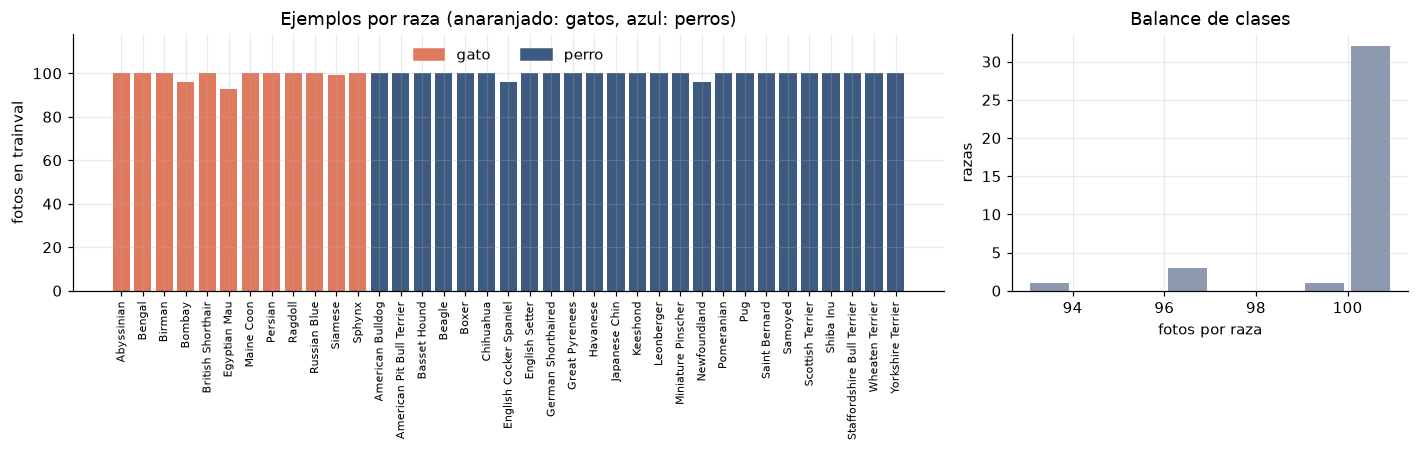

Entre 93 y 100 fotos por raza en trainval; el azar acierta 2.7% de las veces.


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
orden = np.argsort(es_gato.astype(int) * -1, kind="stable")           # gatos primero
cuentas = np.bincount(y_tv, minlength=K)
ax[0].bar(range(K), cuentas[orden], color=[C_GATO if es_gato[i] else C_PERRO for i in orden])
ax[0].set_xticks(range(K)); ax[0].set_xticklabels([nombres[i] for i in orden], rotation=90, fontsize=7)
ax[0].set_ylabel("fotos en trainval"); ax[0].set_title("Ejemplos por raza (anaranjado: gatos, azul: perros)")
ax[0].set_ylim(0, 118)
ax[0].legend(handles=[mpatches.Patch(color=C_GATO, label="gato"), mpatches.Patch(color=C_PERRO, label="perro")], frameon=False, ncol=2, loc="upper center")
ax[1].hist(cuentas, bins=range(cuentas.min(), cuentas.max() + 2), color=C_CLAS, rwidth=.85)
ax[1].set_xlabel("fotos por raza"); ax[1].set_ylabel("razas"); ax[1].set_title("Balance de clases")
plt.tight_layout(); plt.show()
print(f"Entre {cuentas.min()} y {cuentas.max()} fotos por raza en trainval; el azar acierta {1/K:.1%} de las veces.")

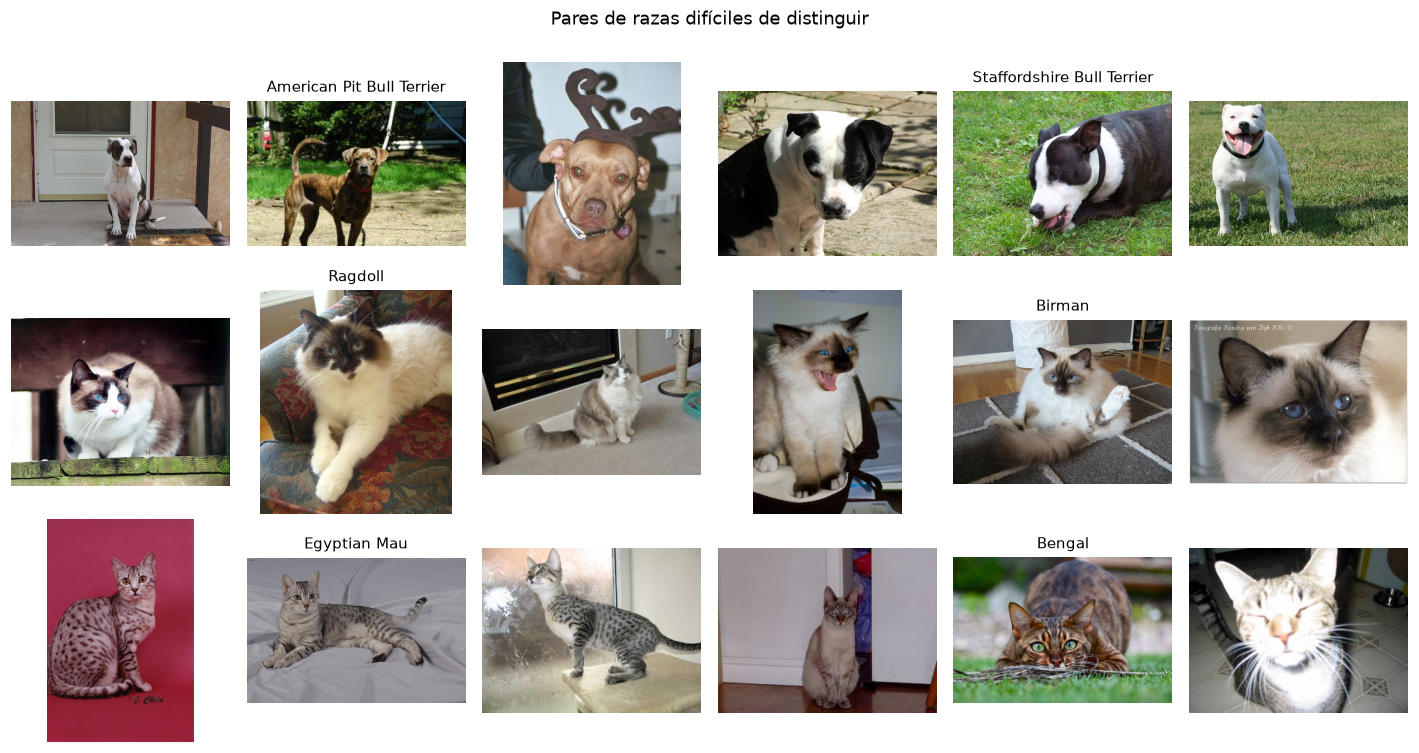

In [4]:
# Tres pares de razas que a simple vista se confunden
pares = [("American Pit Bull Terrier", "Staffordshire Bull Terrier"), ("Ragdoll", "Birman"), ("Egyptian Mau", "Bengal")]
ds_vis = torchvision.datasets.OxfordIIITPet(DATA, split="trainval", target_types="category", download=False)
rng_v = np.random.default_rng(3)
fig, ax = plt.subplots(3, 6, figsize=(13, 6.8))
for r, par in enumerate(pares):
    for c, nombre in enumerate(par):
        idx_raza = np.where(y_tv == nombres.index(nombre))[0]
        for k, i in enumerate(rng_v.choice(idx_raza, 3, replace=False)):
            a = ax[r, c * 3 + k]; a.imshow(ds_vis[i][0]); a.axis("off")
            if k == 1: a.set_title(nombre, fontsize=10)
plt.suptitle("Pares de razas difíciles de distinguir", y=1.0); plt.tight_layout(); plt.show()

Lo que se ve confirma que el problema es de **grano fino**: dentro de una misma raza cambian la pose y el fondo más de lo que cambia el aspecto entre razas vecinas. Esperamos que los errores se concentren en pares como estos y no en pares gato–perro.

## 4. Preprocesamiento y reducción de dimensión

Un circuito de $n$ qubits no se puede alimentar con 2 048 números, así que hay que comprimir. Todo lo que depende de los datos se ajusta **solo con el conjunto de entrenamiento** y después se aplica sin reajustar a validación y prueba:

1. **Estandarización** (media 0, varianza 1).
2. **Reducción a $d$ dimensiones**, con dos opciones: *PCA* (no supervisado, el que sugiere el enunciado) y *LDA* (análisis discriminante lineal, supervisado, hasta 36 componentes), que busca justamente las direcciones que separan mejor las clases.
3. **Escalado a $[0,\pi]$** con `MinMaxScaler`. Las rotaciones son $2\pi$-periódicas, así que en $[0,\pi]$ cada valor corresponde a un punto distinto de la esfera de Bloch. En validación y prueba algunos valores pueden salirse un poco de ese intervalo, y es normal.

Como LDA con 2 048 variables y unas 3 000 fotos se sobreajusta con facilidad (hay más variables que ejemplos por clase), primero aplicamos un PCA a 256 componentes y sobre eso el LDA. También probamos una tercera opción, **LDA con *shrinkage*** (`solver="eigen", shrinkage="auto"`, la regularización de Ledoit-Wolf): con unas 85 fotos por raza, la covarianza dentro de cada clase se estima con mucho ruido, y el LDA sin regularizar separa las razas de entrenamiento mejor de lo que separa las fotos nuevas. Justo abajo lo medimos con la validación. Cuál de las tres reducciones usamos al final lo decide la validación del QNN, en la sección 6. Dejamos la clase `Reductor` para poder repetir el proceso con cualquier subconjunto, lo que necesitaremos en la versión jerárquica.

In [5]:
# Partición estratificada: 85 % entrenamiento / 15 % validación dentro de trainval
idx_tr, idx_va = train_test_split(np.arange(len(y_tv)), test_size=0.15, stratify=y_tv, random_state=SEED)
Xtr, ytr = X_tv[idx_tr], y_tv[idx_tr]
Xva, yva = X_tv[idx_va], y_tv[idx_va]
print(f"entrenamiento={len(ytr)}  validación={len(yva)}  prueba={len(y_te)}")

class Reductor:
    """Estandariza -> PCA, LDA o LDA con shrinkage -> escala a [0, pi]. Todo se ajusta con los datos que se le pasan en fit."""
    def __init__(self, tipo="pca", d=12):
        # tipo: "pca", "lda" o "lda_s" (LDA con shrinkage)
        self.tipo, self.d, self.shrink = ("lda" if tipo.startswith("lda") else tipo), d, tipo == "lda_s"
    def fit(self, X, y):
        self.sc = StandardScaler().fit(X)
        Z = self.sc.transform(X)
        if self.tipo == "pca":
            self.red = PCA(self.d, random_state=SEED).fit(Z)
        else:
            self.pre = PCA(min(256, Z.shape[0] - 1, Z.shape[1]), random_state=SEED).fit(Z)
            lda = (LinearDiscriminantAnalysis(solver="eigen", shrinkage="auto", n_components=self.d) if self.shrink
                   else LinearDiscriminantAnalysis(n_components=self.d))
            self.red = lda.fit(self.pre.transform(Z), y)
        self.ang = MinMaxScaler((0, np.pi)).fit(self._proyecta(X))
        return self
    def _proyecta(self, X):
        Z = self.sc.transform(X)
        if self.tipo == "lda": Z = self.pre.transform(Z)
        return self.red.transform(Z)
    def transform(self, X):
        return self.ang.transform(self._proyecta(X))

entrenamiento=3128  validación=552  prueba=3669


**¿Hace falta regularizar el LDA?** Lo medimos con un clasificador que no entrena nada, los centroides más cercanos, sobre las 16 variables de LDA con y sin *shrinkage*. Si el F1 en entrenamiento queda muy por encima del de validación, el LDA está memorizando las fotos con las que se ajustó. Solo miramos entrenamiento y validación.

In [6]:
filas_lda = []
for shrink in (False, True):
    R_ = Reductor("lda_s" if shrink else "lda", 16).fit(Xtr, ytr)
    nc_ = NearestCentroid().fit(R_.transform(Xtr), ytr)
    filas_lda.append({"LDA": "con shrinkage" if shrink else "sin regularizar",
                      "F1 entrenamiento": f1_score(ytr, nc_.predict(R_.transform(Xtr)), average="macro"),
                      "F1 validación": f1_score(yva, nc_.predict(R_.transform(Xva)), average="macro")})
display(pd.DataFrame(filas_lda).set_index("LDA").round(3))


,F1 entrenamiento,F1 validación
LDA,,
sin regularizar,0.884,0.844
con shrinkage,0.887,0.882


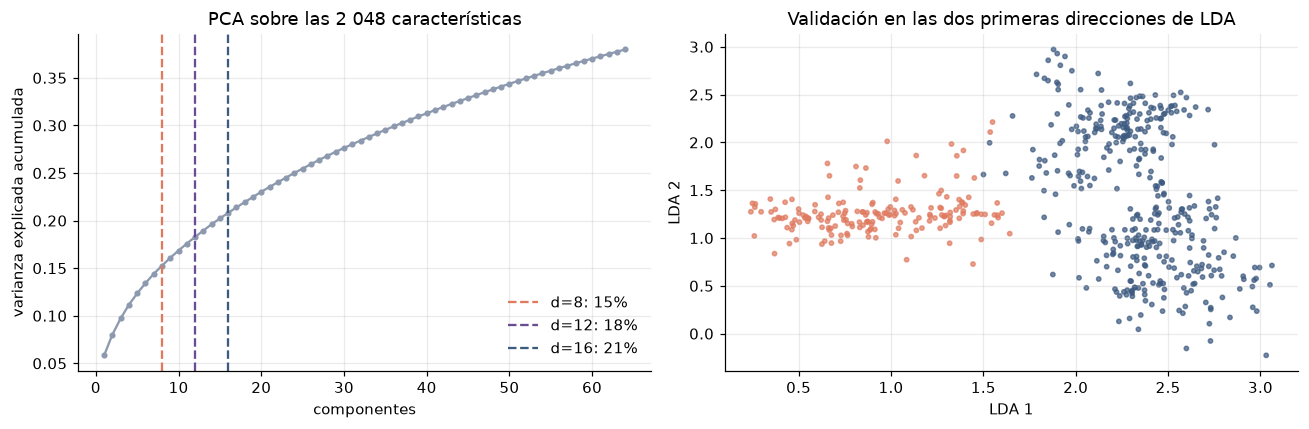

Varianza retenida por PCA: d=8 -> 15.3% | d=12 -> 18.3% | d=16 -> 20.8%


In [7]:
# ¿Cuánta información se queda en d componentes? Curva de PCA (solo entrenamiento)
pca_full = PCA(64, random_state=SEED).fit(StandardScaler().fit_transform(Xtr))
cum = np.cumsum(pca_full.explained_variance_ratio_)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(range(1, 65), cum, "o-", ms=3, color=C_CLAS)
for dd, col in zip((8, 12, 16), (C_GATO, C_QNN, C_PERRO)):
    ax[0].axvline(dd, ls="--", color=col, label=f"d={dd}: {cum[dd-1]:.0%}")
ax[0].set_xlabel("componentes"); ax[0].set_ylabel("varianza explicada acumulada"); ax[0].legend(frameon=False)
ax[0].set_title("PCA sobre las 2 048 características")

# Primeras dos direcciones de LDA (ajustadas con entrenamiento), fotos de validación coloreadas por especie
R = Reductor("lda", 12).fit(Xtr, ytr); Zv = R.transform(Xva)
ax[1].scatter(Zv[:, 0], Zv[:, 1], c=[C_PERRO if e else C_GATO for e in especie(yva)], s=8, alpha=.7)
ax[1].set_title("Validación en las dos primeras direcciones de LDA"); ax[1].set_xlabel("LDA 1"); ax[1].set_ylabel("LDA 2")
plt.tight_layout(); plt.show()
print(f"Varianza retenida por PCA: d=8 -> {cum[7]:.1%} | d=12 -> {cum[11]:.1%} | d=16 -> {cum[15]:.1%}")

Con 8 a 16 componentes el PCA conserva solo entre 15 % y 21 % de la varianza. Es poco: casi toda la información de las 2 048 características se queda fuera, y eso va a pesar en los resultados de **todos** los modelos, no solo los cuánticos. LDA hace otro tipo de compromiso, porque se queda con las direcciones que mejor separan las razas del conjunto de entrenamiento aunque expliquen poca varianza; en el diagrama de la derecha ya se ve que separa bien gatos de perros con solo dos de ellas. Más adelante decidimos entre PCA y LDA con la validación y no con la prueba.

## 5. Los modelos cuánticos

### 5.1 El circuito

Aquí traducimos a código la sección 1.3. `QNN` guarda la forma del circuito (qubits $n$, variables $d$, clases $K$, capas $L$) y se encarga de la lectura, la pérdida y el entrenamiento. Algunas decisiones prácticas:

* Las variables se reparten entre qubits y alternan $R_Y$, $R_Z$ y $R_Y$ (por si algún qubit recibe más de dos). Con $d=2n$ cada qubit recibe exactamente $R_Y$ y $R_Z$.
* Se leen los primeros $n_r=\lceil\log_2 K\rceil$ qubits. Para 37 razas son los 6 del circuito plano; para la especie, solo uno de los 4. La probabilidad de la clase 1 es entonces la del qubit 0 en $|1\rangle$, marginalizando los demás.
* `lectura="z"` activa la segunda forma de leer del Lab 7: valores esperados $\langle Z_q\rangle$ de cada qubit seguidos de una capa lineal clásica $n\to K$. Es un modelo híbrido y por eso lo medimos aparte, en las ablaciones.
* `reupload=False` codifica los datos solo en la primera capa. Eso es un VQC convencional y nos sirve de ablación.

**Dos implementaciones del mismo circuito.** El circuito está definido en PennyLane (`q_probs`, `q_z`); con él dibujamos, contamos recursos y comparamos contra Qiskit. Pero entrenar directamente con ese *QNode* nos salió caro: con el circuito plano, una época tardaba unos 20 s en nuestra laptop, es decir, unos 10 minutos por modelo, y para este proyecto hacen falta más de veinte modelos. La mayor parte de ese tiempo es el costo de armar y derivar cientos de compuertas una por una en Python. Por eso escribimos también un simulador de vector de estado en PyTorch (`probs_t`) que aplica, para cada qubit, el producto de sus compuertas como una sola matriz de $2\times2$ y entrelaza con una permutación de amplitudes. **Es exactamente el mismo circuito**: más abajo comprobamos que las probabilidades de los dos coinciden a precisión de máquina antes de entrenar nada. El entrenamiento y la inferencia usan la versión rápida y la verificación usa la de PennyLane.

In [8]:
def _ry(t):
    c, s = torch.cos(t / 2), torch.sin(t / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(torch.complex128)

def _rz(t):
    e = torch.exp(-0.5j * t.to(torch.complex128)); z = torch.zeros_like(e)
    return torch.stack([torch.stack([e, z], -1), torch.stack([z, e.conj()], -1)], -2)

class QNN:
    """Clasificador variacional con data re-uploading (n qubits, d variables, K clases, L capas)."""

    def __init__(self, n, d, K, L, reupload=True, lectura="probs"):
        self.n, self.d, self.K, self.L = n, d, K, L
        self.reupload, self.lectura = reupload, lectura
        self.nr = max(1, int(np.ceil(np.log2(K))))                 # qubits que se leen
        assert self.nr <= n and n <= d <= 3 * n
        self.vars_q = [list(range(q, d, n)) for q in range(n)]      # variables que entran por cada qubit

        # ---- definición en PennyLane (referencia) ----
        dev = qml.device("default.qubit", wires=n)

        @qml.qnode(dev, interface="autograd", diff_method="backprop")
        def q_probs(x, w, a):
            self.circuito(x, w, a)
            return qml.probs(wires=range(self.nr))

        @qml.qnode(dev, interface="autograd", diff_method="backprop")
        def q_z(x, w, a):
            self.circuito(x, w, a)
            return [qml.expval(qml.PauliZ(q)) for q in range(self.n)]

        self.q_probs, self.q_z = q_probs, q_z

        # ---- datos fijos del simulador rápido: permutación del anillo de CNOT y signos de Z_q ----
        f = np.zeros(2 ** n, dtype=int)
        for b in range(2 ** n):
            bits = [(b >> (n - 1 - i)) & 1 for i in range(n)]
            for q in range(n):
                bits[(q + 1) % n] ^= bits[q]
            f[b] = int("".join(map(str, bits)), 2)
        self.inv = torch.tensor(np.argsort(f))
        L_, l_ = "ABCDEFGH"[:n], "abcdefgh"[:n]                                   # einsum: una matriz de 2x2 por qubit sobre el estado
        self.eq = ",".join(f"z{u}{v}" for u, v in zip(L_, l_)) + f",z{l_}->z{L_}"
        self.Q = [[q for q in range(n) if len(self.vars_q[q]) > k] for k in range(3)]       # qubits que reciben una k-ésima variable
        self.J = [[self.vars_q[q][k] for q in self.Q[k]] for k in range(3)]                 # y cuál variable es
        self.zsig = torch.tensor([[1 - 2 * ((b >> (n - 1 - q)) & 1) for q in range(n)] for b in range(2 ** n)], dtype=torch.float64)

    # ---------------- PennyLane ----------------
    def codifica(self, x, a, l):
        for q in range(self.n):
            for k, j in enumerate(self.vars_q[q]):
                (qml.RY, qml.RZ, qml.RY)[k % 3](a[l, j] * x[..., j], wires=q)

    def circuito(self, x, w, a):
        for l in range(self.L):
            if self.reupload or l == 0:
                self.codifica(x, a, l)
            for q in range(self.n):
                qml.Rot(w[l, q, 0], w[l, q, 1], w[l, q, 2], wires=q)
            for q in range(self.n):
                qml.CNOT(wires=[q, (q + 1) % self.n])

    # ---------------- simulador rápido (PyTorch) ----------------
    def _codificacion(self, x, a, l):
        """Producto de las compuertas de datos de cada qubit: tensor (B, n, 2, 2)."""
        G = {k: fn(a[l, self.J[k]] * x[:, self.J[k]]) for k, fn in enumerate((_ry, _rz, _ry)) if self.Q[k]}
        U = []
        for q in range(self.n):
            u = None
            for k in G:
                if q in self.Q[k]:
                    g = G[k][:, self.Q[k].index(q)]
                    u = g if u is None else g @ u
            U.append(u)
        return torch.stack(U, 1)

    def probs_t(self, x, w, a):
        """Probabilidad de los 2^n estados base. x: (B, d) torch float64; w: (L,n,3); a: (L,d)."""
        B, n = x.shape[0], self.n
        psi = torch.zeros(B, 2 ** n, dtype=torch.complex128); psi[:, 0] = 1
        for l in range(self.L):
            rot = _rz(w[l, :, 2]) @ _ry(w[l, :, 1]) @ _rz(w[l, :, 0])             # Rot(phi, theta, omega) de cada qubit: (n, 2, 2)
            if self.reupload or l == 0:
                U = rot.unsqueeze(0) @ self._codificacion(x, a, l)
            else:
                U = rot.unsqueeze(0).expand(B, n, 2, 2)
            psi = torch.einsum(self.eq, *[U[:, q] for q in range(n)], psi.reshape(B, *[2] * n)).reshape(B, -1)
            psi = psi[:, self.inv]                                               # anillo de CNOT
        return psi.real ** 2 + psi.imag ** 2

    def logits_t(self, p, x):
        pr = self.probs_t(x, p[0], p[1])
        if self.lectura == "probs":
            return p[2] * pr.reshape(len(x), 2 ** self.nr, -1).sum(-1)[:, :self.K]
        return (pr @ self.zsig) @ p[2] + p[3]

    def inicializa(self, rng, beta0):
        T = lambda v: torch.tensor(v, dtype=torch.float64, requires_grad=True)
        w, a = T(rng.uniform(0, 2 * np.pi, (self.L, self.n, 3))), T(np.ones((self.L, self.d)))
        if self.lectura == "probs":
            return [w, a, T(float(beta0))]
        return [w, a, T(rng.normal(0, 0.5, (self.n, self.K))), T(np.zeros(self.K))]

    @property
    def n_params(self):
        na = self.L * self.d if self.reupload else self.d          # sin re-subida solo cuenta la primera capa
        base = 3 * self.L * self.n + na
        return base + (1 if self.lectura == "probs" else self.n * self.K + self.K)

    # ---------------- inferencia ----------------
    def _lote(self, Z, p, bs, fn):
        p = self.params if p is None else p
        p = [torch.as_tensor(np.asarray(t, dtype=float)) for t in p]
        with torch.no_grad():
            return np.vstack([fn(p, torch.as_tensor(Z[i:i + bs], dtype=torch.float64)).numpy() for i in range(0, len(Z), bs)])

    def predict_proba(self, Z, p=None, bs=1500):
        return self._lote(Z, p, bs, lambda p, x: torch.softmax(self.logits_t(p, x), dim=1))

    def probs_estados(self, Z, p=None, bs=1500):
        """Probabilidad exacta de cada estado base de los qubits leídos (para simular shots)."""
        return self._lote(Z, p, bs, lambda p, x: self.probs_t(x, p[0], p[1]).reshape(len(x), 2 ** self.nr, -1).sum(-1))

    # ---------------- entrenamiento ----------------
    def fit(self, Ztr, ytr, Zva, yva, epocas=30, batch=128, lr=0.1, beta0=50.0, seed=0, verbose=False):
        rng = np.random.default_rng(seed)
        p = self.inicializa(rng, beta0)
        opt = torch.optim.Adam(p, lr=lr)
        Zt, yt = torch.as_tensor(Ztr, dtype=torch.float64), torch.as_tensor(ytr)
        hist = dict(perdida=[], val_acc=[], val_f1=[])
        mejor_f1, mejor = -1, None
        t0 = time.time()
        for ep in range(epocas):
            for g in opt.param_groups:
                g["lr"] = lr * 0.5 * (1 + np.cos(np.pi * ep / epocas))        # decaimiento coseno
            orden = rng.permutation(len(Zt)); perd = []
            for i in range(0, len(orden), batch):
                b = torch.as_tensor(orden[i:i + batch])
                opt.zero_grad()
                loss = torch.nn.functional.cross_entropy(self.logits_t(p, Zt[b]), yt[b])
                loss.backward(); opt.step(); perd.append(loss.item())
            pv = self.predict_proba(Zva, p=[t.detach().numpy() for t in p]).argmax(1)
            f1 = f1_score(yva, pv, average="macro")
            hist["perdida"].append(np.mean(perd)); hist["val_acc"].append(accuracy_score(yva, pv)); hist["val_f1"].append(f1)
            if f1 > mejor_f1:                                                   # nos quedamos con la mejor época en validación
                mejor_f1, mejor = f1, [t.detach().numpy().copy() for t in p]
            if verbose and (ep % 5 == 4 or ep == 0):
                print(f"  época {ep+1:02d}  pérdida={hist['perdida'][-1]:.3f}  val_acc={hist['val_acc'][-1]:.3f}  val_F1={f1:.3f}  ({time.time()-t0:.0f} s)")
        self.params, self.hist, self.tiempo = mejor, hist, time.time() - t0
        return self

### 5.2 Comprobación: el simulador rápido y PennyLane son el mismo circuito

Antes de entrenar comparamos, con parámetros aleatorios, las probabilidades de los dos para varias configuraciones: el circuito plano, uno sin re-subida, el de especie (que lee solo un qubit de cuatro) y el de raza de perro (5 qubits, $d=10$, con qubits que reciben una o dos variables) y la lectura $\langle Z\rangle$.

In [9]:
rng_t = np.random.default_rng(5)
configs_t = [dict(n=6, d=12, K=37, L=3), dict(n=6, d=16, K=37, L=2), dict(n=6, d=12, K=37, L=3, reupload=False),
             dict(n=4, d=8, K=2, L=2), dict(n=5, d=10, K=25, L=2), dict(n=6, d=12, K=37, L=2, lectura="z")]
for cfg in configs_t:
    m = QNN(**cfg)
    w = rng_t.uniform(0, 2 * np.pi, (m.L, m.n, 3)); a = rng_t.uniform(.5, 1.5, (m.L, m.d)); x = rng_t.uniform(0, np.pi, (7, m.d))
    p_rapido = m.probs_t(torch.tensor(x), torch.tensor(w), torch.tensor(a)).reshape(7, 2 ** m.nr, -1).sum(-1).numpy()
    p_pl = np.asarray(m.q_probs(pnp.array(x), pnp.array(w), pnp.array(a)))
    err = np.abs(p_rapido - p_pl).max()
    if cfg.get("lectura") == "z":
        z_rapido = (m.probs_t(torch.tensor(x), torch.tensor(w), torch.tensor(a)) @ m.zsig).numpy()
        err = max(err, np.abs(z_rapido - np.stack([np.asarray(t) for t in m.q_z(pnp.array(x), pnp.array(w), pnp.array(a))], 1)).max())
    assert err < 1e-10, (cfg, err)
    print(f"{str(cfg):<66} máx |rápido − PennyLane| = {err:.1e}")

{'n': 6, 'd': 12, 'K': 37, 'L': 3}                                 máx |rápido − PennyLane| = 1.1e-16
{'n': 6, 'd': 16, 'K': 37, 'L': 2}                                 máx |rápido − PennyLane| = 1.5e-16
{'n': 6, 'd': 12, 'K': 37, 'L': 3, 'reupload': False}              máx |rápido − PennyLane| = 1.7e-16
{'n': 4, 'd': 8, 'K': 2, 'L': 2}                                   máx |rápido − PennyLane| = 4.4e-16
{'n': 5, 'd': 10, 'K': 25, 'L': 2}                                 máx |rápido − PennyLane| = 2.8e-16


{'n': 6, 'd': 12, 'K': 37, 'L': 2, 'lectura': 'z'}                 máx |rápido − PennyLane| = 3.4e-16


### 5.3 El circuito, dibujado

Para que se lea, dibujamos una sola capa del circuito plano de 6 qubits (en el modelo real se repite $L$ veces). Las dos primeras rotaciones de cada qubit son la codificación de las variables $x_j$ y $x_{j+6}$, después viene la rotación general $\mathrm{Rot}$ entrenable y por último el anillo de CNOT.

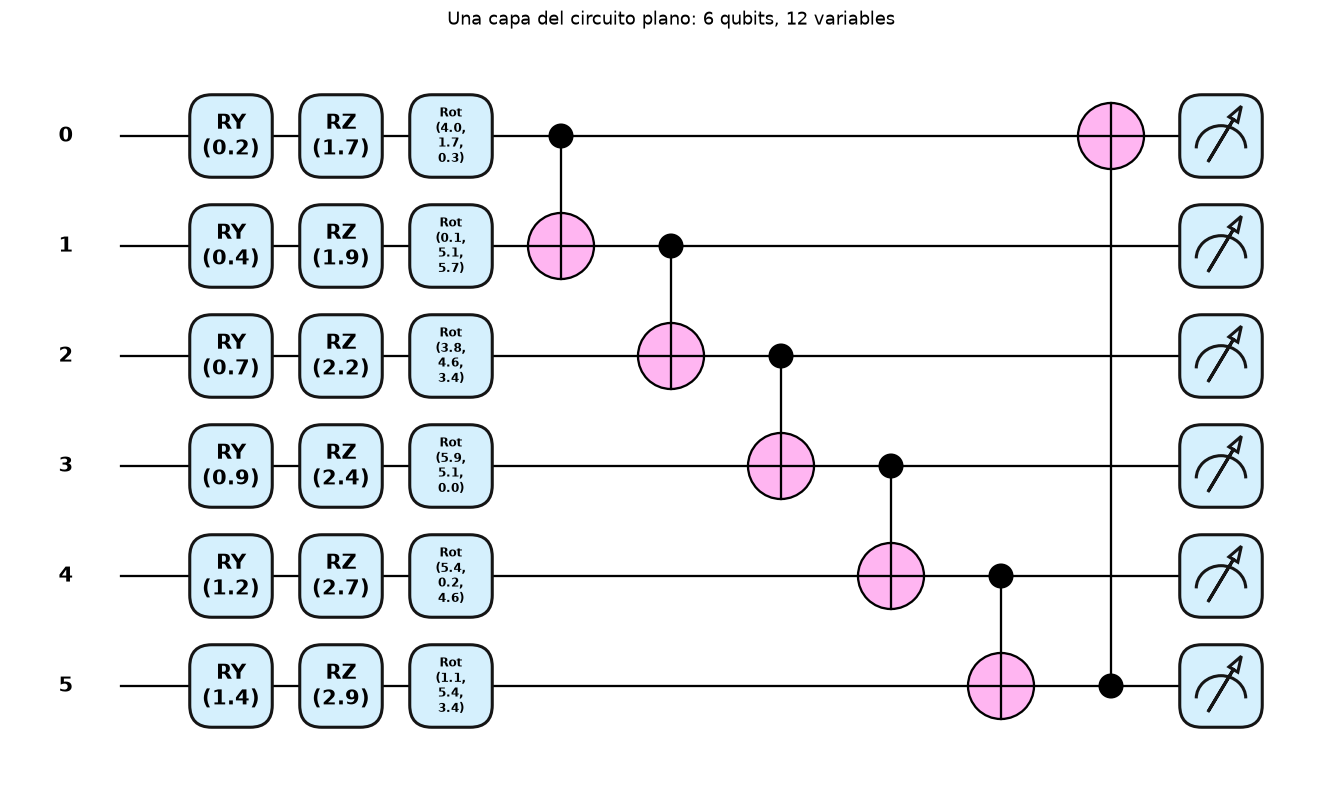

In [10]:
demo = QNN(n=6, d=12, K=K, L=1)
rng0 = np.random.default_rng(0)
w_demo = pnp.array(rng0.uniform(0, 2*np.pi, (1, 6, 3))); a_demo = pnp.array(np.ones((1, 12)))
x_demo = pnp.array(np.linspace(0.2, 2.9, 12))
fig, ax = qml.draw_mpl(demo.q_probs, decimals=1, style="pennylane")(x_demo, w_demo, a_demo)
fig.suptitle("Una capa del circuito plano: 6 qubits, 12 variables", y=1.02); plt.show()

### 5.4 Las dos arquitecturas

El circuito **plano** usa $n=6$ qubits y $L=5$ capas, con $3nL + dL + 1$ parámetros: 151 con $d=12$ y 171 con $d=16$ (el valor de $d$ se elige en la sección 6). El **jerárquico** pone tres circuitos más chicos en serie; abajo está el esquema y la tabla con sus tamaños.

El circuito de especie usa PCA con $d=8$ variables y los de raza usan el mismo tipo de reducción (PCA o LDA) que el plano, cada uno ajustado solo con las fotos de su especie. Con eso cada etapa ve las direcciones que mejor describen *su* problema y no un compromiso entre los 37 casos.

In [11]:
class Jerarquico:
    """Especie (4 qubits) -> raza de gato (4 qubits) o de perro (5 qubits). P(y|x) = P(especie|x) P(y|especie, x)."""

    def __init__(self, red="pca", d_sp=8, d_gato=8, d_perro=10, L_sp=3, L_raza=5, reupload=True):
        self.red, self.reupload = red, reupload
        self.cls_gato, self.cls_perro = np.where(es_gato)[0], np.where(~es_gato)[0]
        self.cfg = {"especie": (4, d_sp, 2, L_sp), "gato": (4, d_gato, len(self.cls_gato), L_raza),
                    "perro": (5, d_perro, len(self.cls_perro), L_raza)}
        self.red_etapa = {"especie": "pca", "gato": red, "perro": red}
        self.m = {k: QNN(n, d, Kk, L, reupload) for k, (n, d, Kk, L) in self.cfg.items()}

    @property
    def n_params(self): return sum(m.n_params for m in self.m.values())

    def _datos(self, etapa, X, y):
        """Devuelve (X, y_local) con solo las fotos que le tocan a cada etapa."""
        if etapa == "especie": return X, especie(y)
        cls = self.cls_gato if etapa == "gato" else self.cls_perro
        mk = np.isin(y, cls)
        return X[mk], np.searchsorted(cls, y[mk])

    def fit(self, Xtr, ytr, Xva, yva, epocas=30, seed=0, verbose=False, **kw):
        self.R = {}
        for etapa, m in self.m.items():
            Xa, ya = self._datos(etapa, Xtr, ytr); Xb, yb = self._datos(etapa, Xva, yva)
            self.R[etapa] = Reductor(self.red_etapa[etapa], self.cfg[etapa][1]).fit(Xa, ya)
            if verbose: print(f"[{etapa}] {len(ya)} fotos de entrenamiento, {m.n} qubits, {m.n_params} parámetros")
            m.fit(self.R[etapa].transform(Xa), ya, self.R[etapa].transform(Xb), yb, epocas=epocas, seed=seed, verbose=verbose, **kw)
        self.tiempo = sum(m.tiempo for m in self.m.values())
        return self

    def etapas(self, X):
        return {e: self.m[e].predict_proba(self.R[e].transform(X)) for e in self.m}

    def predict_proba(self, X):
        E = self.etapas(X)
        P = np.zeros((len(X), K))
        P[:, self.cls_gato] = E["especie"][:, [0]] * E["gato"]
        P[:, self.cls_perro] = E["especie"][:, [1]] * E["perro"]
        return P

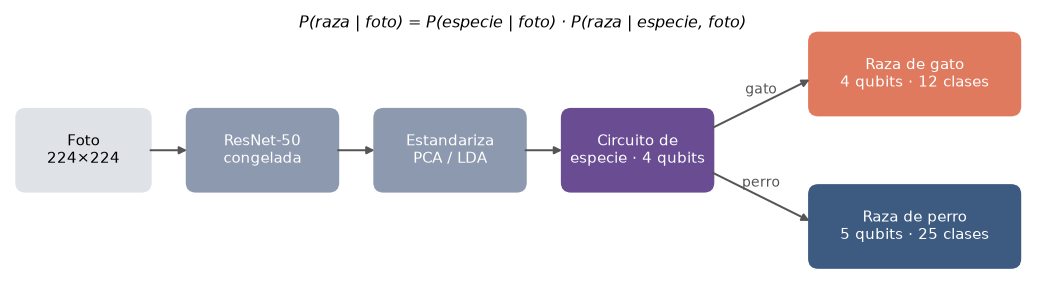

Parámetros del circuito plano (L=5): 151 con d=12, 171 con d=16
         qubits  variables  clases  capas  parámetros
especie       4          8       2      3          61
gato          4          8      12      5         101
perro         5         10      25      5         126
Parámetros del jerárquico en total: 288


In [12]:
# Esquema de la arquitectura jerárquica
fig, ax = plt.subplots(figsize=(12, 3.3)); ax.axis("off"); ax.set_xlim(0, 12); ax.set_ylim(0, 3.3)
def caja(x, y, w, h, txt, col, tc="white"):
    ax.add_patch(mpatches.FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.12", fc=col, ec="none"))
    ax.text(x + w/2, y + h/2, txt, ha="center", va="center", color=tc, fontsize=9.5)
def flecha(x0, y0, x1, y1, txt=None):
    ax.annotate("", (x1, y1), (x0, y0), arrowprops=dict(arrowstyle="-|>", color="#555", lw=1.3))
    if txt: ax.text((x0+x1)/2, (y0+y1)/2 + .12, txt, fontsize=9, color="#555", ha="center")
caja(0.1, 1.2, 1.5, .9, "Foto\n224×224", "#dfe3e8", "black")
caja(2.1, 1.2, 1.7, .9, "ResNet-50\ncongelada", C_CLAS)
caja(4.3, 1.2, 1.7, .9, "Estandariza\nPCA / LDA", C_CLAS)
caja(6.5, 1.2, 1.7, .9, "Circuito de\nespecie · 4 qubits", C_QNN)
caja(9.4, 2.1, 2.4, .9, "Raza de gato\n4 qubits · 12 clases", C_GATO)
caja(9.4, 0.3, 2.4, .9, "Raza de perro\n5 qubits · 25 clases", C_PERRO)
flecha(1.6, 1.65, 2.1, 1.65); flecha(3.8, 1.65, 4.3, 1.65); flecha(6.0, 1.65, 6.5, 1.65)
flecha(8.2, 1.9, 9.4, 2.5, "gato"); flecha(8.2, 1.4, 9.4, 0.8, "perro")
ax.text(6, 3.1, "P(raza | foto) = P(especie | foto) · P(raza | especie, foto)", ha="center", fontsize=10.5, style="italic")
plt.show()

jer_demo = Jerarquico()
print(f"Parámetros del circuito plano (L=5): {QNN(6, 12, K, 5).n_params} con d=12, {QNN(6, 16, K, 5).n_params} con d=16")
print(pd.DataFrame({etapa: dict(qubits=m.n, variables=m.d, clases=m.K, capas=m.L, parámetros=m.n_params)
                    for etapa, m in jer_demo.m.items()}).T)
print(f"Parámetros del jerárquico en total: {jer_demo.n_params}")

Dos observaciones antes de seguir. La jerárquica tiene **más parámetros en total** (unos 290) que la plana (151 con $d=12$, 171 con $d=16$), aunque cada circuito individual es más chico; en las comparaciones lo tenemos presente y usamos baselines de ambos tamaños. Y el *softmax* de temperatura se entrena de forma independiente en cada etapa.

## 6. Entrenamiento

Usamos Adam con tasa inicial 0.1 y decaimiento coseno, minibatch de 128, 30 épocas, ángulos iniciales uniformes en $[0,2\pi)$, escalas $\alpha=1$ y temperatura inicial $\beta=50$. En la propuesta habíamos escrito 0.05 y minibatch de 64; los cambiamos después de probar unas cuantas combinaciones (tasa entre 0.05 y 0.15, $\beta$ inicial entre 20 y 80, lote de 64 o 128) con una semilla y **mirando solo la validación**. Esa búsqueda la hicimos con la primera versión del preprocesamiento (LDA sin regularizar). Todas quedaron entre 0.62 y 0.67 de F1 macro, de modo que no hay un ajuste fino que presumir: elegimos la que entrenaba más rápido. El conjunto de prueba no intervino. En cada época calculamos el F1 macro en validación y nos quedamos con los parámetros de la mejor.

Primero necesitamos decidir **qué reducción usar** (PCA, LDA o LDA con *shrinkage*, y con cuántas variables). Entrenamos el circuito plano con cada combinación, semilla 0, y comparamos en **validación**. Como referencia barata incluimos también una regresión logística sobre las mismas variables.

In [13]:
EPOCAS = 2 if MODO_RAPIDO else 30
SEMILLAS = (0,) if MODO_RAPIDO else (0, 1, 2)
L_PLANO = 5

def metricas(P, y):
    """top-1, top-5, F1 macro, accuracy de especie y fracción de errores que ocurren dentro de la misma especie."""
    pred = P.argmax(1)
    top5 = np.mean((np.argsort(-P, axis=1)[:, :5] == y[:, None]).any(1))
    err = pred != y
    intra = np.mean(especie(pred[err]) == especie(y[err])) if err.any() else np.nan
    return dict(acc=accuracy_score(y, pred), top5=top5, f1_macro=f1_score(y, pred, average="macro"),
                acc_especie=np.mean(especie(pred) == especie(y)), err_misma_especie=intra)

filas = []
NOMBRE_RED = {"pca": "PCA", "lda": "LDA", "lda_s": "LDA + shrinkage"}
for tipo in ("pca", "lda", "lda_s"):
    for dd in (8, 12, 16):
        R = Reductor(tipo, dd).fit(Xtr, ytr)
        Ztr_, Zva_ = R.transform(Xtr), R.transform(Xva)
        m = QNN(6, dd, K, L_PLANO).fit(Ztr_, ytr, Zva_, yva, epocas=EPOCAS, seed=0)
        lr_ = LogisticRegression(max_iter=3000).fit(Ztr_, ytr)
        mv = metricas(m.predict_proba(Zva_), yva)
        filas.append(dict(reducción=NOMBRE_RED[tipo], código=tipo, d=dd, params=m.n_params, val_acc=mv["acc"], val_F1_QNN=mv["f1_macro"],
                          val_F1_logística=f1_score(yva, lr_.predict(Zva_), average="macro"), seg=m.tiempo))
        print(f"{NOMBRE_RED[tipo]} d={dd:2d}: val_F1 QNN={mv['f1_macro']:.3f} | regresión logística={filas[-1]['val_F1_logística']:.3f} | {m.tiempo:.0f} s")
sel = pd.DataFrame(filas)
display(sel.round(3))

PCA d= 8: val_F1 QNN=0.324 | regresión logística=0.673 | 87 s


PCA d=12: val_F1 QNN=0.402 | regresión logística=0.776 | 113 s


PCA d=16: val_F1 QNN=0.442 | regresión logística=0.829 | 129 s


LDA d= 8: val_F1 QNN=0.615 | regresión logística=0.796 | 106 s


LDA d=12: val_F1 QNN=0.668 | regresión logística=0.834 | 103 s


LDA d=16: val_F1 QNN=0.687 | regresión logística=0.858 | 100 s


LDA + shrinkage d= 8: val_F1 QNN=0.594 | regresión logística=0.824 | 82 s


LDA + shrinkage d=12: val_F1 QNN=0.643 | regresión logística=0.851 | 104 s


LDA + shrinkage d=16: val_F1 QNN=0.624 | regresión logística=0.904 | 114 s


,reducción,código,d,params,val_acc,val_F1_QNN,val_F1_logística,seg
0,PCA,pca,8,131,0.350,0.324,0.673,86.663
1,PCA,pca,12,151,0.429,0.402,0.776,112.634
2,PCA,pca,16,171,0.466,0.442,0.829,129.429
3,LDA,lda,8,131,0.616,0.615,0.796,106.356
4,LDA,lda,12,151,0.670,0.668,0.834,102.726
5,LDA,lda,16,171,0.690,0.687,0.858,100.449
6,LDA + shrinkage,lda_s,8,131,0.623,0.594,0.824,82.013
7,LDA + shrinkage,lda_s,12,151,0.658,0.643,0.851,103.864
8,LDA + shrinkage,lda_s,16,171,0.629,0.624,0.904,113.997


Elegimos LDA con d=16 (mejor F1 macro de validación del QNN: 0.687)


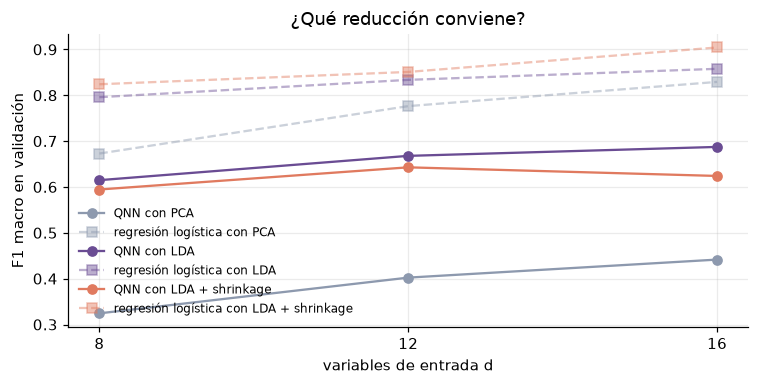

In [14]:
mejor = sel.loc[sel.val_F1_QNN.idxmax()]
RED, D_PLANO = mejor["código"], int(mejor["d"])
print(f"Elegimos {NOMBRE_RED[RED]} con d={D_PLANO} (mejor F1 macro de validación del QNN: {mejor.val_F1_QNN:.3f})")

fig, ax = plt.subplots(figsize=(7, 3.6))
for tipo, col in (("PCA", C_CLAS), ("LDA", C_QNN), ("LDA + shrinkage", C_GATO)):
    s = sel[sel["reducción"] == tipo]
    ax.plot(s.d, s.val_F1_QNN, "o-", color=col, label=f"QNN con {tipo}")
    ax.plot(s.d, s.val_F1_logística, "s--", color=col, alpha=.45, label=f"regresión logística con {tipo}")
ax.set_xticks([8, 12, 16]); ax.set_xlabel("variables de entrada d"); ax.set_ylabel("F1 macro en validación")
ax.set_title("¿Qué reducción conviene?"); ax.legend(frameon=False, fontsize=8); plt.tight_layout(); plt.show()

LDA supera con claridad a PCA, como esperábamos. Lo interesante es el *shrinkage*: mejora a la regresión logística (con $d=16$ pasa de 0.858 a 0.904 de F1 en validación), pero **empeora al QNN** (de 0.687 a 0.624). Como la decisión es sobre el modelo cuántico, nos quedamos con LDA sin regularizar y $d=16$, y todos los modelos, clásicos y cuánticos, reciben esa misma entrada. Volvemos a esto en las conclusiones.

## 7. Modelos principales

Con la reducción ya elegida, entrenamos los dos modelos finales con tres semillas cada uno (la semilla cambia solo la inicialización y el orden de los minibatches; la partición es siempre la misma).

In [15]:
R_plano = Reductor(RED, D_PLANO).fit(Xtr, ytr)
Ztr, Zva, Zte = R_plano.transform(Xtr), R_plano.transform(Xva), R_plano.transform(X_te)

plano = []
for sd in SEMILLAS:
    m = QNN(6, D_PLANO, K, L_PLANO).fit(Ztr, ytr, Zva, yva, epocas=EPOCAS, seed=sd, verbose=(sd == 0))
    m.test_P = m.predict_proba(Zte); m.test = metricas(m.test_P, y_te)
    plano.append(m)
    print(f"plano · semilla {sd}: {m.tiempo:.0f} s | test acc={m.test['acc']:.3f}  top5={m.test['top5']:.3f}  F1={m.test['f1_macro']:.3f}\n")

  época 01  pérdida=2.933  val_acc=0.366  val_F1=0.331  (4 s)


  época 05  pérdida=1.549  val_acc=0.556  val_F1=0.529  (20 s)


  época 10  pérdida=1.324  val_acc=0.609  val_F1=0.589  (39 s)


  época 15  pérdida=1.171  val_acc=0.636  val_F1=0.620  (59 s)


  época 20  pérdida=1.055  val_acc=0.667  val_F1=0.651  (77 s)


  época 25  pérdida=0.985  val_acc=0.665  val_F1=0.660  (96 s)


  época 30  pérdida=0.942  val_acc=0.683  val_F1=0.683  (113 s)


plano · semilla 0: 113 s | test acc=0.683  top5=0.913  F1=0.678



plano · semilla 1: 116 s | test acc=0.646  top5=0.900  F1=0.646



plano · semilla 2: 109 s | test acc=0.674  top5=0.915  F1=0.671



In [16]:
jerar = []
for sd in SEMILLAS:
    j = Jerarquico(red=RED).fit(Xtr, ytr, Xva, yva, epocas=EPOCAS, seed=sd, verbose=(sd == 0))
    j.test_P = j.predict_proba(X_te); j.test = metricas(j.test_P, y_te)
    jerar.append(j)
    print(f"jerárquico · semilla {sd}: {j.tiempo:.0f} s | test acc={j.test['acc']:.3f}  top5={j.test['top5']:.3f}  F1={j.test['f1_macro']:.3f}\n")

[especie] 3128 fotos de entrenamiento, 4 qubits, 61 parámetros


  época 01  pérdida=0.921  val_acc=0.886  val_F1=0.860  (1 s)


  época 05  pérdida=0.067  val_acc=0.973  val_F1=0.968  (4 s)


  época 10  pérdida=0.041  val_acc=0.976  val_F1=0.973  (7 s)


  época 15  pérdida=0.041  val_acc=0.951  val_F1=0.945  (10 s)


  época 20  pérdida=0.023  val_acc=0.976  val_F1=0.973  (13 s)


... (17 outputs left out)

  época 30  pérdida=0.501  val_acc=0.775  val_F1=0.775  (36 s)


jerárquico · semilla 0: 68 s | test acc=0.759  top5=0.959  F1=0.755



jerárquico · semilla 1: 85 s | test acc=0.772  top5=0.958  F1=0.771



jerárquico · semilla 2: 64 s | test acc=0.758  top5=0.951  F1=0.755



### 7.1 ¿Ayuda la jerarquía o solo tiene más parámetros?

El jerárquico tiene unos 290 parámetros y el plano 171, así que una mejora del jerárquico podría deberse solo al tamaño. Para separarlo entrenamos también un **plano con $L=8$ capas** (273 parámetros, casi los mismos que el jerárquico), con las mismas tres semillas. Más adelante (sección 9) hacemos la misma pregunta con un modelo clásico: una regresión logística plana frente a una jerárquica.

In [17]:
L_GRANDE = 8
plano8 = []
for sd in SEMILLAS:
    m = QNN(6, D_PLANO, K, L_GRANDE).fit(Ztr, ytr, Zva, yva, epocas=EPOCAS, seed=sd)
    m.test_P = m.predict_proba(Zte); m.test = metricas(m.test_P, y_te)
    plano8.append(m)
    print(f"plano L={L_GRANDE} · semilla {sd}: {m.tiempo:.0f} s | {m.n_params} parámetros | test acc={m.test['acc']:.3f}  "
          f"top5={m.test['top5']:.3f}  F1={m.test['f1_macro']:.3f}")


plano L=8 · semilla 0: 183 s | 273 parámetros | test acc=0.732  top5=0.933  F1=0.731


plano L=8 · semilla 1: 185 s | 273 parámetros | test acc=0.706  top5=0.918  F1=0.703


plano L=8 · semilla 2: 206 s | 273 parámetros | test acc=0.707  top5=0.928  F1=0.705


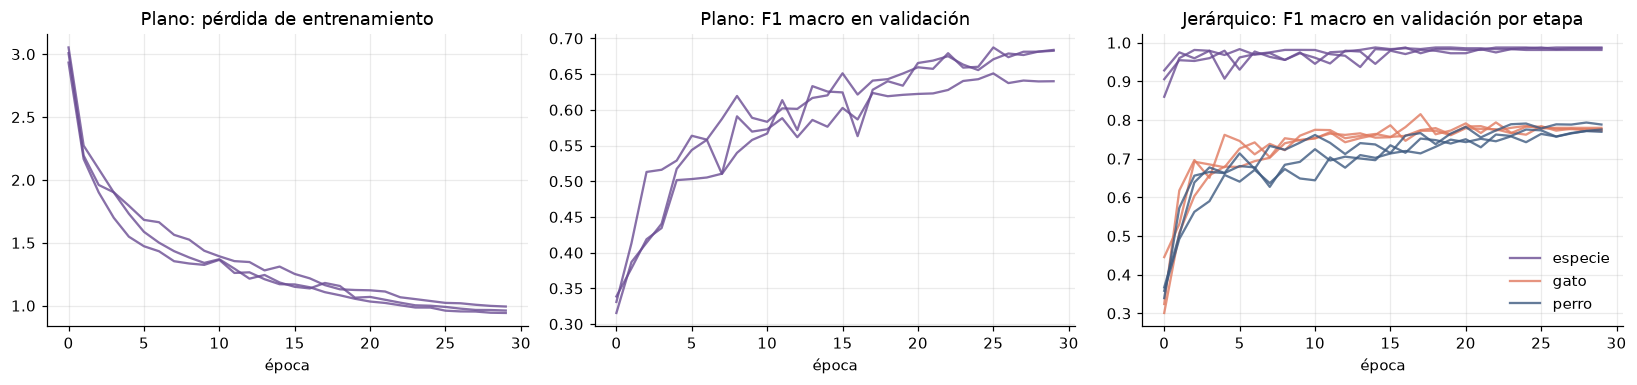

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for m in plano:
    ax[0].plot(m.hist["perdida"], color=C_QNN, alpha=.8); ax[1].plot(m.hist["val_f1"], color=C_QNN, alpha=.8)
ax[0].set_title("Plano: pérdida de entrenamiento"); ax[1].set_title("Plano: F1 macro en validación")
for e, col in (("especie", C_QNN), ("gato", C_GATO), ("perro", C_PERRO)):
    for k, j in enumerate(jerar):
        ax[2].plot(j.m[e].hist["val_f1"], color=col, alpha=.8, label=e if k == 0 else None)
ax[2].set_title("Jerárquico: F1 macro en validación por etapa"); ax[2].legend(frameon=False)
for a in ax: a.set_xlabel("época")
plt.tight_layout(); plt.show()

## 8. Resultados de los modelos cuánticos en prueba

El conjunto de prueba solo se ha usado para reportar números; ninguna decisión (reducción, $d$, época, semilla) dependió de él. Para las gráficas detalladas tomamos, de cada arquitectura, la semilla con mejor F1 en **validación** y no en prueba.

In [19]:
def val_f1(modelo, kind):
    P = modelo.predict_proba(Zva) if kind == "plano" else modelo.predict_proba(Xva)
    return metricas(P, yva)["f1_macro"]

mejor_plano = max(plano, key=lambda m: val_f1(m, "plano"))
mejor_jer = max(jerar, key=lambda j: val_f1(j, "jer"))

def resumen(lista, nombre, n_par):
    df = pd.DataFrame([m.test for m in lista])
    fila = {"modelo": nombre, "parámetros": n_par}
    for c in ("acc", "top5", "f1_macro", "acc_especie", "err_misma_especie"):
        fila[c] = f"{df[c].mean():.3f} ± {df[c].std(ddof=0):.3f}"
    return fila

res_q = pd.DataFrame([resumen(plano, f"QNN plano (6 qubits, L={L_PLANO})", plano[0].n_params),
                      resumen(plano8, f"QNN plano (6 qubits, L={L_GRANDE})", plano8[0].n_params),
                      resumen(jerar, "QNN jerárquico (4+4+5 qubits)", jerar[0].n_params)]).set_index("modelo")
res_q.columns = ["parámetros", "accuracy", "top-5", "F1 macro", "acc. especie", "errores en misma especie"]
print(f"Media ± desviación estándar sobre {len(SEMILLAS)} semillas, conjunto de prueba ({len(y_te)} fotos)")
display(res_q)

Media ± desviación estándar sobre 3 semillas, conjunto de prueba (3669 fotos)


,parámetros,accuracy,top-5,F1 macro,acc. especie,errores en misma especie
modelo,,,,,,
"QNN plano (6 qubits, L=5)",171,0.668 ± 0.016,0.909 ± 0.007,0.665 ± 0.014,0.938 ± 0.003,0.814 ± 0.007
"QNN plano (6 qubits, L=8)",273,0.715 ± 0.012,0.926 ± 0.006,0.713 ± 0.013,0.945 ± 0.010,0.809 ± 0.028
QNN jerárquico (4+4+5 qubits),288,0.763 ± 0.006,0.956 ± 0.004,0.760 ± 0.007,0.985 ± 0.005,0.938 ± 0.021


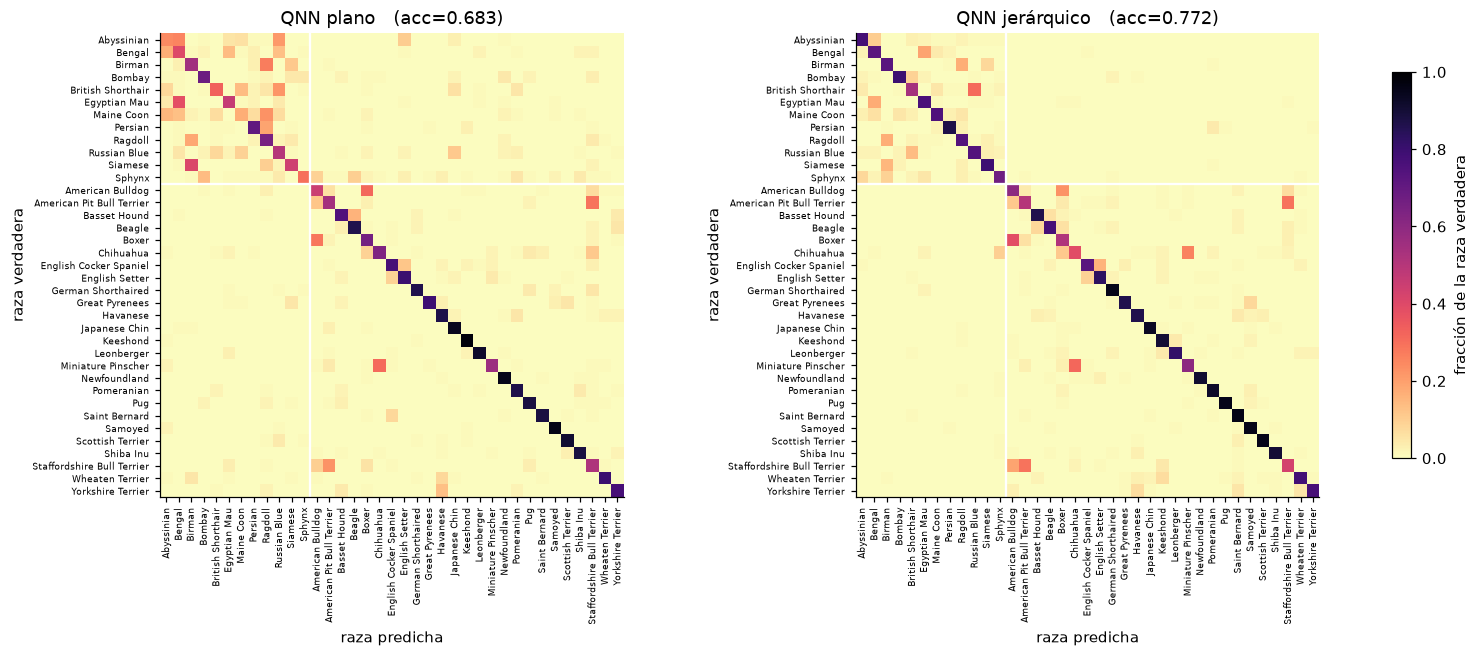

In [20]:
def matriz_ordenada(y, pred):
    orden = np.concatenate([np.where(es_gato)[0], np.where(~es_gato)[0]])           # gatos primero, luego perros
    C = confusion_matrix(y, pred, labels=orden).astype(float)
    return C / C.sum(1, keepdims=True), orden

fig, ax = plt.subplots(1, 2, figsize=(17, 7.6), gridspec_kw={"wspace": 0.5})
for a, (titulo, P) in zip(ax, [("QNN plano", mejor_plano.test_P), ("QNN jerárquico", mejor_jer.test_P)]):
    C, orden = matriz_ordenada(y_te, P.argmax(1))
    im = a.imshow(C, cmap="magma_r", vmin=0, vmax=1)
    a.axhline(es_gato.sum() - .5, color="w", lw=1.5); a.axvline(es_gato.sum() - .5, color="w", lw=1.5)
    a.set_xticks(range(K)); a.set_yticks(range(K))
    a.set_xticklabels([nombres[i] for i in orden], rotation=90, fontsize=6); a.set_yticklabels([nombres[i] for i in orden], fontsize=6)
    a.set_title(f"{titulo}   (acc={accuracy_score(y_te, P.argmax(1)):.3f})"); a.grid(False)
    a.set_xlabel("raza predicha"); a.set_ylabel("raza verdadera")
fig.colorbar(im, ax=ax, shrink=.6, label="fracción de la raza verdadera")
plt.show()

In [21]:
# ¿Qué razas se confunden más? (QNN jerárquico y plano, mejores semillas)
def pares_confundidos(P, y, top=8):
    pred = P.argmax(1); C = confusion_matrix(y, pred, labels=range(K)); np.fill_diagonal(C, 0)
    idx = np.dstack(np.unravel_index(np.argsort(-C.ravel())[:top], C.shape))[0]
    return pd.DataFrame([dict(verdadera=nombres[i], predicha=nombres[j], fotos=int(C[i, j]),
                              de=int((y == i).sum())) for i, j in idx])
t1, t2 = pares_confundidos(mejor_plano.test_P, y_te), pares_confundidos(mejor_jer.test_P, y_te)
display(pd.concat([t1.add_prefix("plano · "), t2.add_prefix("jerárquico · ")], axis=1))

,plano · verdadera,plano · predicha,plano · fotos,plano · de,jerárquico · verdadera,jerárquico · predicha,jerárquico · fotos,jerárquico · de
0,Siamese,Birman,41,100,Boxer,American Bulldog,38,99
1,Egyptian Mau,Bengal,37,97,Miniature Pinscher,Chihuahua,32,100
2,American Bulldog,Boxer,32,100,British Shorthair,Russian Blue,31,100
3,Miniature Pinscher,Chihuahua,31,100,American Pit Bull Terrier,Staffordshire Bull Terrier,29,100
4,American Pit Bull Terrier,Staffordshire Bull Terrier,29,100,Staffordshire Bull Terrier,American Pit Bull Terrier,26,89
5,Boxer,American Bulldog,28,99,Chihuahua,Miniature Pinscher,26,100
6,Birman,Ragdoll,27,100,American Bulldog,Boxer,23,100
7,Abyssinian,Bengal,25,98,Bengal,Egyptian Mau,19,100


### 8.1 ¿De dónde vienen los errores de la jerarquía?

El riesgo de la jerarquía es que un error en la especie ya no tiene arreglo en la etapa siguiente. Medimos cuánto pesa cada fuente de error en prueba: **especie incorrecta** (la foto de un perro se manda al circuito de gatos o al revés) frente a **raza incorrecta dentro de la especie correcta**.

In [22]:
def descompone(P, y):
    pred = P.argmax(1); err = pred != y
    sp_mal = especie(pred) != especie(y)
    return dict(error_total=err.mean(), por_especie=(err & sp_mal).mean(), por_raza_misma_especie=(err & ~sp_mal).mean())

dd_ = pd.DataFrame({"QNN plano": descompone(mejor_plano.test_P, y_te), "QNN jerárquico": descompone(mejor_jer.test_P, y_te)}).T
display((dd_ * 100).round(2).rename(columns={"error_total": "error total (%)", "por_especie": "…por especie equivocada (%)",
                                             "por_raza_misma_especie": "…por raza equivocada, misma especie (%)"}))

E = mejor_jer.etapas(X_te)
sp_acc = np.mean(E["especie"].argmax(1) == especie(y_te))
m_g = np.isin(y_te, mejor_jer.cls_gato); m_p = ~m_g
acc_g = np.mean(E["gato"].argmax(1)[m_g] == np.searchsorted(mejor_jer.cls_gato, y_te[m_g]))
acc_p = np.mean(E["perro"].argmax(1)[m_p] == np.searchsorted(mejor_jer.cls_perro, y_te[m_p]))
print(f"Etapas del jerárquico por separado (con la especie verdadera conocida para las razas): "
      f"especie={sp_acc:.3f} | raza de gato={acc_g:.3f} | raza de perro={acc_p:.3f}")

,error total (%),…por especie equivocada (%),"…por raza equivocada, misma especie (%)"
QNN plano,31.73,5.72,26.00
QNN jerárquico,22.84,1.25,21.59


Etapas del jerárquico por separado (con la especie verdadera conocida para las razas): especie=0.986 | raza de gato=0.750 | raza de perro=0.792


## 9. Comparación con modelos clásicos

Para que la comparación sea justa, los clasificadores clásicos reciben **exactamente la misma entrada** que el circuito plano (las mismas $d$ variables ya en $[0,\pi]$, las mismas particiones). Así medimos el efecto del modelo y no el de la información. Tomamos:

* **Referencias geométricas:** centroides más cercanos (el análogo clásico del *swap test*) y *k*-NN.
* **Capacidad parecida a la del circuito:** una regresión logística multinomial y dos MLP con una sola capa oculta, de 3 neuronas (199 parámetros, cerca de los 171 del plano) y de 5 (307, cerca de los 288 del jerárquico). Para que la comparación sea justa, estos MLP se entrenan **igual que el circuito**: Adam con decaimiento coseno, minibatch de 128, 30 épocas, la mejor época según validación y tres semillas. Su tasa de aprendizaje se elige con la validación, igual que hicimos con el QNN.
* **Jerarquía clásica:** la misma descomposición especie → raza, con las mismas reducciones por etapa que el QNN jerárquico, pero con una regresión logística en cada etapa. Comparada con la regresión logística plana, dice cuánto ayuda la jerarquía por sí misma, sin circuito de por medio.
* **Modelos más grandes:** MLP de 64-32 y SVM con kernel RBF.
* **Cota superior:** regresión logística sobre las 2 048 características originales, para saber cuánto se pierde por comprimir.

No ajustamos los hiperparámetros de ninguno con el conjunto de prueba.

In [23]:
class MLPAdam:
    """MLP de una capa oculta (tanh) entrenado como el QNN: Adam, coseno, minibatch 128, mejor época en validación."""
    def __init__(self, h, lr=0.01):
        self.h, self.lr = h, lr

    def fit(self, Ztr, ytr, Zva, yva, epocas=30, batch=128, seed=0):
        torch.manual_seed(seed); rng = np.random.default_rng(seed)
        self.net = torch.nn.Sequential(torch.nn.Linear(Ztr.shape[1], self.h), torch.nn.Tanh(),
                                       torch.nn.Linear(self.h, K)).double()
        opt = torch.optim.Adam(self.net.parameters(), lr=self.lr)
        Zt, yt = torch.as_tensor(Ztr, dtype=torch.float64), torch.as_tensor(ytr)
        mejor_f1, t0 = -1, time.time()
        for ep in range(epocas):
            for g in opt.param_groups:
                g["lr"] = self.lr * 0.5 * (1 + np.cos(np.pi * ep / epocas))
            orden = rng.permutation(len(Zt))
            for i in range(0, len(orden), batch):
                b = torch.as_tensor(orden[i:i + batch])
                opt.zero_grad()
                torch.nn.functional.cross_entropy(self.net(Zt[b]), yt[b]).backward(); opt.step()
            f1 = f1_score(yva, self.predict_proba(Zva).argmax(1), average="macro")
            if f1 > mejor_f1:
                mejor_f1, mejor = f1, {k: v.clone() for k, v in self.net.state_dict().items()}
        self.net.load_state_dict(mejor); self.val_f1, self.tiempo = mejor_f1, time.time() - t0
        return self

    def predict_proba(self, Z):
        with torch.no_grad():
            return torch.softmax(self.net(torch.as_tensor(Z, dtype=torch.float64)), 1).numpy()

    @property
    def n_params(self): return sum(p.numel() for p in self.net.parameters())

# Tasa de aprendizaje de cada MLP elegida con la validación (semilla 0), como hicimos con el QNN
LR_MLP = {}
for h in (3, 5):
    val = {lr: MLPAdam(h, lr).fit(Ztr, ytr, Zva, yva, epocas=EPOCAS, seed=0).val_f1 for lr in (0.003, 0.01, 0.03, 0.1, 0.3)}
    LR_MLP[h] = max(val, key=val.get)
    print(f"MLP con {h} neuronas: F1 de validación por tasa {({k: round(v, 3) for k, v in val.items()})} -> elegimos {LR_MLP[h]}")


class JerarquicoClasico(Jerarquico):
    """La misma jerarquía especie -> raza y las mismas reducciones por etapa, con un clasificador clásico en cada etapa."""
    def __init__(self, fabrica, red="pca"):
        super().__init__(red=red); self.fabrica = fabrica

    def fit(self, Xtr, ytr):
        self.R, self.c = {}, {}
        t0 = time.time()
        for etapa in self.m:
            Xa, ya = self._datos(etapa, Xtr, ytr)
            self.R[etapa] = Reductor(self.red_etapa[etapa], self.cfg[etapa][1]).fit(Xa, ya)
            self.c[etapa] = self.fabrica().fit(self.R[etapa].transform(Xa), ya)
        self.tiempo = time.time() - t0
        return self

    def etapas(self, X):
        return {e: self.c[e].predict_proba(self.R[e].transform(X)) for e in self.c}

    @property
    def n_params(self): return int(sum(c.coef_.size + c.intercept_.size for c in self.c.values()))


MLP con 3 neuronas: F1 de validación por tasa {0.003: 0.172, 0.01: 0.378, 0.03: 0.551, 0.1: 0.395, 0.3: 0.001} -> elegimos 0.03


MLP con 5 neuronas: F1 de validación por tasa {0.003: 0.458, 0.01: 0.724, 0.03: 0.788, 0.1: 0.655, 0.3: 0.001} -> elegimos 0.03


In [24]:
def puntuaciones(m, Z):
    """Probabilidades (o algo equivalente para ordenar) de cada clase."""
    if hasattr(m, "predict_proba"): return m.predict_proba(Z)
    return -((Z[:, None, :] - m.centroids_[None]) ** 2).sum(-1)               # centroides: -distancia^2

def n_par_mlp(m): return int(sum(c.size for c in m.coefs_) + sum(b.size for b in m.intercepts_))

S2048 = StandardScaler().fit(Xtr); F_tr, F_te = S2048.transform(Xtr), S2048.transform(X_te)

definidos = [
    ("Centroides más cercanos",           lambda s: NearestCentroid(),                                          "d"),
    ("k-NN (k=5)",                         lambda s: KNeighborsClassifier(5),                                    "d"),
    ("Regresión logística",                lambda s: LogisticRegression(max_iter=3000),                          "d"),
    ("MLP 64-32",                          lambda s: MLPClassifier((64, 32), max_iter=1500, random_state=s),      "d"),
    ("SVM RBF",                            lambda s: CalibratedClassifierCV(SVC(C=10, random_state=SEED), ensemble=False), "d"),
    ("Regresión logística (2 048 car.)",   lambda s: LogisticRegression(max_iter=500),                           "full"),
]
estocasticos = {"MLP 64-32"}

clasicos, filas = {}, []
for nombre, fab, entrada in definidos:
    Xa, Xb = (Ztr, Zte) if entrada == "d" else (F_tr, F_te)
    ms = []
    for s in (SEMILLAS if nombre in estocasticos else (SEED,)):
        t0 = time.time(); m = fab(s).fit(Xa, ytr); tt = time.time() - t0
        ms.append((metricas(puntuaciones(m, Xb), y_te), m, tt))
    clasicos[nombre] = ms[0][1]
    df = pd.DataFrame([x[0] for x in ms]); m0 = ms[0][1]
    npar = n_par_mlp(m0) if isinstance(m0, MLPClassifier) else (m0.coef_.size + m0.intercept_.size if hasattr(m0, "coef_") else np.nan)
    filas.append(dict(modelo=nombre, tipo="clásico", parámetros=npar, acc=df.acc.mean(), top5=df.top5.mean(), f1_macro=df.f1_macro.mean(),
                      f1_std=df.f1_macro.std(ddof=0), seg_entrenamiento=np.mean([x[2] for x in ms])))
# MLP pequeños entrenados como el QNN (tres semillas)
for h, etiqueta in ((3, "≈ plano"), (5, "≈ jerárquico")):
    ms = [MLPAdam(h, LR_MLP[h]).fit(Ztr, ytr, Zva, yva, epocas=EPOCAS, seed=s) for s in SEMILLAS]
    df = pd.DataFrame([metricas(m.predict_proba(Zte), y_te) for m in ms])
    filas.append(dict(modelo=f"MLP-Adam ({h} neuronas) {etiqueta}", tipo="clásico", parámetros=ms[0].n_params, acc=df.acc.mean(),
                      top5=df.top5.mean(), f1_macro=df.f1_macro.mean(), f1_std=df.f1_macro.std(ddof=0),
                      seg_entrenamiento=np.mean([m.tiempo for m in ms])))

# Jerarquía clásica: regresión logística en cada etapa, con las mismas reducciones que el QNN jerárquico
jer_log = JerarquicoClasico(lambda: LogisticRegression(max_iter=3000), red=RED).fit(Xtr, ytr)
jer_log.test = metricas(jer_log.predict_proba(X_te), y_te)
filas.append(dict(modelo="Regresión logística jerárquica", tipo="clásico", parámetros=jer_log.n_params, acc=jer_log.test["acc"],
                  top5=jer_log.test["top5"], f1_macro=jer_log.test["f1_macro"], f1_std=0.0, seg_entrenamiento=jer_log.tiempo))

for nombre, lista in (("QNN plano", plano), (f"QNN plano L={L_GRANDE}", plano8), ("QNN jerárquico", jerar)):
    df = pd.DataFrame([m.test for m in lista])
    filas.append(dict(modelo=nombre, tipo="cuántico", parámetros=lista[0].n_params, acc=df.acc.mean(), top5=df.top5.mean(),
                      f1_macro=df.f1_macro.mean(), f1_std=df.f1_macro.std(ddof=0), seg_entrenamiento=np.mean([m.tiempo for m in lista])))
comp = pd.DataFrame(filas).set_index("modelo").sort_values("f1_macro", ascending=False)
display(comp.round(3))

,tipo,parámetros,acc,top5,f1_macro,f1_std,seg_entrenamiento
modelo,,,,,,,
Regresión logística (2 048 car.),clásico,75813.0,0.911,0.992,0.911,0.000,1.154
Regresión logística jerárquica,clásico,392.0,0.850,0.992,0.848,0.000,2.090
Regresión logística,clásico,629.0,0.849,0.991,0.848,0.000,0.641
SVM RBF,clásico,NaN,0.848,0.994,0.846,0.000,1.645
k-NN (k=5),clásico,NaN,0.843,0.965,0.842,0.000,0.001
Centroides más cercanos,clásico,NaN,0.834,0.989,0.832,0.000,0.006
MLP 64-32,clásico,4389.0,0.833,0.990,0.832,0.004,4.597
QNN jerárquico,cuántico,288.0,0.763,0.956,0.760,0.007,72.385
MLP-Adam (5 neuronas) ≈ jerárquico,clásico,307.0,0.755,0.982,0.748,0.009,1.162


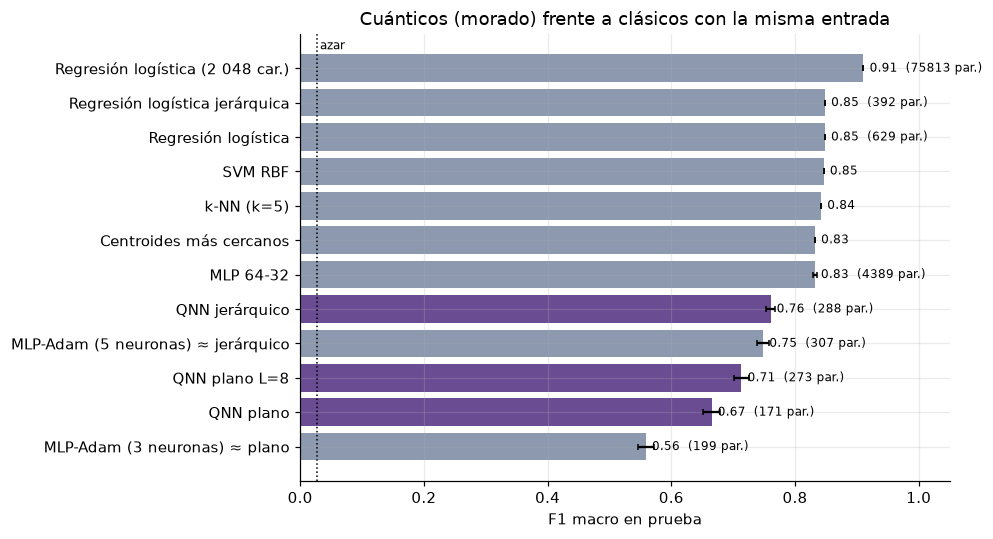

In [25]:
c = comp.sort_values("f1_macro")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(c.index, c.f1_macro, xerr=c.f1_std, color=[C_QNN if t == "cuántico" else C_CLAS for t in c.tipo], capsize=2)
for i, (v, p) in enumerate(zip(c.f1_macro, c.parámetros)):
    ax.text(v + .01, i, f"{v:.2f}" + (f"  ({int(p)} par.)" if not np.isnan(p) else ""), va="center", fontsize=8)
ax.axvline(1 / K, color="k", ls=":", lw=1); ax.text(1 / K + .005, len(c) - .45, "azar", fontsize=8)
ax.set_xlabel("F1 macro en prueba"); ax.set_xlim(0, 1.05); ax.set_title("Cuánticos (morado) frente a clásicos con la misma entrada")
plt.tight_layout(); plt.show()

## 10. Ablaciones

Aquí buscamos entender qué parte del circuito está haciendo el trabajo. Todas se hacen sobre el circuito plano, con la semilla 0 y el mismo presupuesto de entrenamiento. Con una sola semilla las diferencias pequeñas no son concluyentes, y así las vamos a leer. El caso $L=8$ es la semilla 0 del plano de la sección 7.1, que también tiene resultados con tres semillas.

* **Profundidad** $L\in\{1,2,3,5,8\}$.
* **Re-subida de datos**: con y sin ella, con $L=5$ (sin re-subida es un VQC convencional, con menos parámetros porque las escalas $\alpha$ solo importan en la primera capa).
* **Forma de leer el circuito**: probabilidades de estados base con *softmax* de temperatura (lectura A del Lab 7) frente a valores esperados $\langle Z_q\rangle$ con una capa lineal clásica encima (lectura B). Esta última agrega $6\cdot37+37=259$ parámetros clásicos, así que no es una comparación a igualdad de tamaño y la leeremos con cuidado.

La comparación entre plano y jerárquico ya la tenemos en la sección 8. La elección de reducción y de $d$ está en la sección 6.

L=1                              params=  35    25 s  acc=0.111  F1=0.096


L=2                              params=  69    48 s  acc=0.401  F1=0.361


L=3                              params= 103    79 s  acc=0.554  F1=0.523


L=5 sin re-subida                params= 107   120 s  acc=0.570  F1=0.552


L=5 lectura ⟨Z⟩ + capa lineal    params= 429   130 s  acc=0.741  F1=0.731


,parámetros,accuracy,top5,F1_macro,seg
L=5 (principal),171.0,0.683,0.913,0.678,113.330
L=8,273.0,0.732,0.933,0.731,182.982
L=1,35.0,0.111,0.258,0.096,24.803
L=2,69.0,0.401,0.693,0.361,48.392
L=3,103.0,0.554,0.824,0.523,79.399
L=5 sin re-subida,107.0,0.570,0.900,0.552,119.621
L=5 lectura ⟨Z⟩ + capa lineal,429.0,0.741,0.959,0.731,130.316


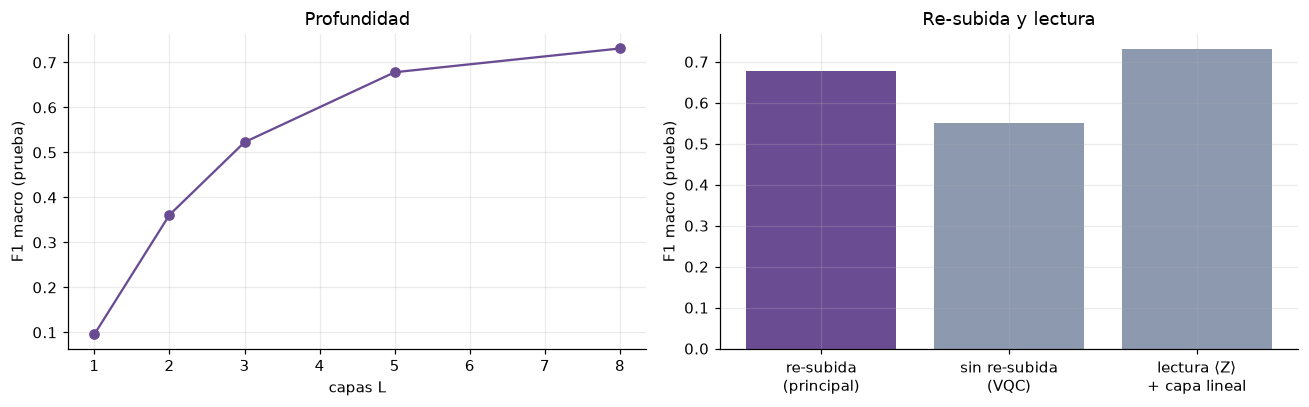

In [26]:
abl = {f"L={L_PLANO} (principal)": plano[0]}
abl["L=8"] = plano8[0]                                   # ya entrenado en la sección 7.1 (semilla 0)
configs = [("L=1", dict(L=1)), ("L=2", dict(L=2)), ("L=3", dict(L=3)),
           (f"L={L_PLANO} sin re-subida", dict(L=L_PLANO, reupload=False)),
           (f"L={L_PLANO} lectura ⟨Z⟩ + capa lineal", dict(L=L_PLANO, lectura="z"))]
for nombre, kw in configs:
    m = QNN(6, D_PLANO, K, **kw).fit(Ztr, ytr, Zva, yva, epocas=EPOCAS, seed=0)
    m.test_P = m.predict_proba(Zte); m.test = metricas(m.test_P, y_te)
    abl[nombre] = m
    print(f"{nombre:<32} params={m.n_params:4d}  {m.tiempo:4.0f} s  acc={m.test['acc']:.3f}  F1={m.test['f1_macro']:.3f}")

tab_abl = pd.DataFrame({k: dict(parámetros=m.n_params, accuracy=m.test["acc"], top5=m.test["top5"], F1_macro=m.test["f1_macro"], seg=m.tiempo)
                        for k, m in abl.items()}).T
display(tab_abl.round(3))

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
LL = [("L=1", 1), ("L=2", 2), ("L=3", 3), (f"L={L_PLANO} (principal)", L_PLANO), ("L=8", 8)]
ax[0].plot([l for _, l in LL], [abl[k].test["f1_macro"] for k, _ in LL], "o-", color=C_QNN)
ax[0].set_xlabel("capas L"); ax[0].set_ylabel("F1 macro (prueba)"); ax[0].set_title("Profundidad")
otros = [f"L={L_PLANO} (principal)", f"L={L_PLANO} sin re-subida", f"L={L_PLANO} lectura ⟨Z⟩ + capa lineal"]
ax[1].bar(["re-subida\n(principal)", "sin re-subida\n(VQC)", "lectura ⟨Z⟩\n+ capa lineal"], [abl[k].test["f1_macro"] for k in otros], color=[C_QNN, C_CLAS, C_CLAS])
ax[1].set_ylabel("F1 macro (prueba)"); ax[1].set_title("Re-subida y lectura")
plt.tight_layout(); plt.show()

## 11. Muestreo finito y costo en hardware

### 11.1 ¿Qué pasa con pocos *shots*?

En un dispositivo real no obtenemos las probabilidades exactas, sino frecuencias de $S$ mediciones. Con 37 clases repartidas en 64 estados, cada raza recibe muy pocas cuentas cuando $S$ es chico, y esto afecta a este problema más que al de 7 clases. Tomamos el circuito plano ya entrenado, calculamos las probabilidades exactas de los 64 estados y simulamos $S$ mediciones de cada foto sacando cuentas de una distribución multinomial. Para un dispositivo ideal sin ruido de compuertas eso es equivalente a ejecutar el circuito $S$ veces. Se predice la raza cuyo estado tuvo más cuentas.

Evaluación exacta (S = ∞): accuracy = 0.683
S=   100: accuracy = 0.518 ± 0.006
S=   500: accuracy = 0.643 ± 0.007


S=  2000: accuracy = 0.676 ± 0.002
S= 10000: accuracy = 0.681 ± 0.001


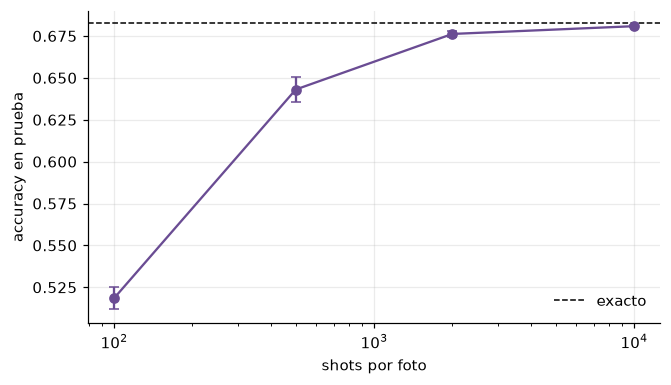

In [27]:
P64 = mejor_plano.probs_estados(Zte)                          # (N, 64): probabilidad exacta de cada estado base
P64 = P64 / P64.sum(1, keepdims=True)
exacto = accuracy_score(y_te, P64[:, :K].argmax(1))
print(f"Evaluación exacta (S = ∞): accuracy = {exacto:.3f}")

rng_s = np.random.default_rng(123)
shots_res = {}
for S in (100, 500, 2000, 10000):
    accs = []
    for rep in range(3):
        cuentas = rng_s.multinomial(S, P64)
        accs.append(accuracy_score(y_te, cuentas[:, :K].argmax(1)))
    shots_res[S] = (np.mean(accs), np.std(accs))
    print(f"S={S:6d}: accuracy = {shots_res[S][0]:.3f} ± {shots_res[S][1]:.3f}")

fig, ax = plt.subplots(figsize=(6.2, 3.6))
ax.errorbar(list(shots_res), [v[0] for v in shots_res.values()], [v[1] for v in shots_res.values()], fmt="o-", color=C_QNN, capsize=3)
ax.axhline(exacto, color="k", ls="--", lw=1, label="exacto"); ax.set_xscale("log")
ax.set_xlabel("shots por foto"); ax.set_ylabel("accuracy en prueba"); ax.legend(frameon=False); plt.tight_layout(); plt.show()

### 11.2 Verificación con Qiskit y profundidad del circuito

Reconstruimos los circuitos entrenados en Qiskit, de forma independiente a PennyLane, y comparamos las probabilidades. Es una comprobación de que nuestra definición del circuito es la que creemos que es (orden de las compuertas, convención de los qubits). Después los transpilamos a un conjunto de compuertas nativas típico de hardware superconductor (`rz`, `sx`, `x`, `cx`) y contamos profundidad y CNOT.

In [28]:
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector

def qiskit_circuito(m, x, w, a):
    qc = QuantumCircuit(m.n)
    for l in range(m.L):
        if m.reupload or l == 0:
            for q in range(m.n):
                for k, j in enumerate(m.vars_q[q]):
                    (qc.ry, qc.rz, qc.ry)[k % 3](float(a[l, j] * x[j]), q)
        for q in range(m.n):
            phi, th, om = map(float, w[l, q]); qc.rz(phi, q); qc.ry(th, q); qc.rz(om, q)     # Rot = RZ(om) RY(th) RZ(phi)
        for q in range(m.n): qc.cx(q, (q + 1) % m.n)
    return qc

def qiskit_probs(m, x, w, a):
    p = Statevector(qiskit_circuito(m, x, w, a)).probabilities()                # orden little-endian de Qiskit
    p = p.reshape([2] * m.n).transpose(range(m.n - 1, -1, -1)).reshape(-1)       # -> orden de PennyLane
    return p.reshape(2 ** m.nr, -1).sum(1)                                       # marginal sobre los qubits que se leen

modelos_ver = {"plano": (mejor_plano, Zte[:25])}
for e in ("especie", "gato", "perro"):
    modelos_ver[f"jerárquico · {e}"] = (mejor_jer.m[e], mejor_jer.R[e].transform(X_te[:25]))

filas = []
for nombre, (m, Zs) in modelos_ver.items():
    w, a = np.asarray(m.params[0]), np.asarray(m.params[1])
    err = max(np.abs(qiskit_probs(m, z, w, a) - np.asarray(m.q_probs(pnp.array(z), w, a))).max() for z in Zs)
    assert err < 1e-9, (nombre, err)
    tq = transpile(qiskit_circuito(m, Zs[0], w, a), basis_gates=["rz", "sx", "x", "cx"], optimization_level=1)
    ops = dict(tq.count_ops())
    filas.append(dict(circuito=nombre, qubits=m.n, error_máx_vs_PennyLane=f"{err:.1e}", profundidad=tq.depth(),
                      CNOT=ops.get("cx", 0), compuertas_totales=sum(ops.values()), parámetros=m.n_params))
display(pd.DataFrame(filas).set_index("circuito"))

,qubits,error_máx_vs_PennyLane,profundidad,CNOT,compuertas_totales,parámetros
circuito,,,,,,
plano,6,1.7e-16,55,30,180,171
jerárquico · especie,4,7.8e-16,27,12,72,61
jerárquico · gato,4,5.0e-16,45,20,120,101
jerárquico · perro,5,2.8e-16,50,25,150,126


### 11.3 Costo de entrenar y de usar el modelo en hardware

En simulación el gradiente sale de un solo *backward pass*. En un dispositivo real habría que usar la regla de desplazamiento de parámetros (*parameter-shift*), que evalúa el circuito dos veces por cada parámetro del circuito y por cada muestra. Con $S$ *shots* por evaluación:

$$
\text{shots por época}\;=\;N_{\text{train}}\cdot 2\,|\boldsymbol\theta_{\text{circ}}|\cdot S .
$$

Abajo también imprimimos los recursos que reporta `qml.specs`. No coinciden con la tabla de Qiskit de la sección 11.2, y es esperado: `qml.specs` cuenta cada `Rot` como una sola compuerta y no transpila, mientras que Qiskit descompone cada rotación en compuertas nativas (`rz`, `sx`, `x`, `cx`), lo que da más compuertas y algo más de profundidad. Para estimar el costo en hardware, la cifra que cuenta es la de Qiskit.

In [29]:
th_circ = lambda m: 3 * m.L * m.n + m.L * m.d                      # parámetros que viven dentro del circuito (sin la temperatura)
S_ = 1000
por_epoca = len(Xtr) * 2 * th_circ(mejor_plano) * S_
print(f"Entrenar el plano con parameter-shift y S={S_}: {por_epoca:,.0f} shots por época -> {por_epoca * 30:,.0f} shots en 30 épocas")
print(f"Inferencia de {len(y_te)} fotos con S={S_}: {len(y_te) * S_:,} shots")
sp = qml.specs(mejor_plano.q_probs)(pnp.array(Zte[0]), np.asarray(mejor_plano.params[0]), np.asarray(mejor_plano.params[1]))
print("\nRecursos del circuito plano (qml.specs):"); print(sp.resources)

Entrenar el plano con parameter-shift y S=1000: 1,063,520,000 shots por época -> 31,905,600,000 shots en 30 épocas
Inferencia de 3669 fotos con S=1000: 3,669,000 shots

Recursos del circuito plano (qml.specs):
Wire allocations: 6
Total gates: 140
Gate counts:
- RY: 50
- RZ: 30
- Rot: 30
- CNOT: 30
Measurements:
- probs(all wires): 1
Depth: 50


## 12. Conclusiones y discusión

### 12.1 Los números

Todo sobre el conjunto de prueba (3 669 fotos), con las mismas partición y entrada para todos. Los modelos con ± son la media y la desviación estándar de tres semillas.

| Modelo | Parámetros | Accuracy | Top-5 | F1 macro |
|---|---:|:---:|:---:|:---:|
| **QNN jerárquico** (4+4+5 qubits) | 288 | 0.763 ± 0.006 | 0.956 | 0.760 ± 0.007 |
| **QNN plano** (6 qubits, $L=8$) | 273 | 0.715 ± 0.012 | 0.926 | 0.713 ± 0.013 |
| **QNN plano** (6 qubits, $L=5$) | 171 | 0.668 ± 0.016 | 0.909 | 0.665 ± 0.014 |
| MLP-Adam, 5 neuronas ocultas | 307 | 0.755 | 0.982 | 0.748 ± 0.009 |
| MLP-Adam, 3 neuronas ocultas | 199 | 0.580 | 0.961 | 0.559 ± 0.013 |
| Centroides más cercanos | – | 0.834 | 0.989 | 0.832 |
| Regresión logística | 629 | 0.849 | 0.991 | 0.848 |
| Regresión logística jerárquica | 392 | 0.850 | 0.992 | 0.848 |
| SVM RBF | – | 0.848 | 0.994 | 0.846 |
| MLP 64-32 | 4 389 | 0.833 | 0.990 | 0.832 |
| Regresión logística con las 2 048 características | 75 813 | 0.911 | 0.992 | 0.911 |

(El azar acierta 2.7 %. Con 3 669 fotos, el error estándar de una *accuracy* de 0.8 es de unos 0.7 puntos, así que diferencias de uno o dos puntos no cuentan.)

### 12.2 Lo que encontramos

**Funciona, y la jerarquía ayuda por sí misma, no solo por tamaño.** Un circuito de 6 qubits con 171 parámetros identifica la raza correcta en dos de cada tres fotos, y en nueve de cada diez la tiene entre sus cinco primeras sugerencias. El jerárquico sube a 76 % de *accuracy* y 95.6 % en top-5. Como el jerárquico tiene más parámetros (288 contra 171), entrenamos también un plano con $L=8$ capas y 273 parámetros, con tres semillas: llega a 0.713 ± 0.013 de F1, contra 0.760 ± 0.007 del jerárquico. Con casi el mismo tamaño, la jerarquía gana unos cinco puntos, mucho más que la variación entre semillas. Más capas sí ayudan al plano (de 0.665 a 0.713), pero no alcanzan.

La descomposición de errores dice por qué. La etapa de especie acierta 98.6 % de las veces, así que casi todo el error del jerárquico (21.6 de 22.8 puntos) es de raza dentro de la especie correcta, mientras que el plano manda a la especie equivocada un 5.7 % de las fotos.

**La jerarquía ayuda al circuito, no al problema.** Con la regresión logística, la versión jerárquica (con las mismas reducciones por etapa) empata con la plana: 0.848 contra 0.848. Al modelo clásico le da igual partir el problema; al circuito no. Nuestra lectura es que la ventaja de la jerarquía está en la **lectura del circuito**: el plano tiene que repartir 37 clases entre 64 estados base, mientras que cada circuito del jerárquico solo distingue 2, 12 o 25 clases. Esto coincide con la ablación de la lectura (más abajo), donde leer $\langle Z_q\rangle$ con una capa lineal también mejora al plano.

**A igual tamaño, el QNN aguanta frente a un MLP entrenado igual.** Comparamos con MLP de una capa oculta entrenados con el mismo procedimiento que el circuito (Adam, decaimiento coseno, 30 épocas, mejor época en validación, tasa de aprendizaje elegida con la validación, tres semillas). Con unos 300 parámetros, el QNN jerárquico (0.760 ± 0.007) queda ligeramente por encima del MLP de 5 neuronas (0.748 ± 0.009); la diferencia es pequeña, del orden del error estándar, así que lo leemos como un empate. Con unos 200 parámetros, el QNN plano (0.665 ± 0.014, 171 parámetros) supera claramente al MLP de 3 neuronas (0.559 ± 0.013, 199 parámetros). Un detalle: los MLP tienen mejor top-5 que los QNN, aunque peor top-1.

**Frente a los modelos clásicos sin límite de tamaño, no hay ventaja.** Con las mismas 16 variables, una regresión logística de 629 parámetros saca 0.85 de F1, la SVM 0.85 y hasta los centroides más cercanos, que no entrenan nada, llegan a 0.83. El QNN jerárquico queda nueve puntos por debajo de la logística. La ventaja del QNN a tamaño fijo desaparece en cuanto el modelo clásico puede usar unos cientos de parámetros más, y ese es el resultado que cuenta.

**La entrada pesa más que el modelo.** La regresión logística sobre las 2 048 características originales llega a 0.911, contra 0.848 con 16 variables: comprimir cuesta unos seis puntos a todos los modelos. Y la forma de comprimir importó más que cualquier decisión del circuito. Con PCA el QNN plano apenas pasaba de 0.44 de F1 en validación con $d=16$; con LDA llegó a 0.69. Hay que decirlo con claridad: LDA usa las etiquetas, así que parte del trabajo de separar razas ya está hecho antes de que el circuito vea el dato.

**Lo que es bueno para los clásicos no siempre es bueno para el circuito.** El LDA con *shrinkage* mejora la separación de las fotos nuevas (el F1 de los centroides en validación sube de 0.844 a 0.882) y la regresión logística en validación pasa de 0.858 a 0.904 con $d=16$. Pero el QNN en validación **empeora**, de 0.687 a 0.624. La validación eligió LDA sin regularizar, y con esa elección se hicieron todas las comparaciones; los clásicos podrían rendir algo mejor con su propio preprocesamiento. Una hipótesis para este comportamiento, que no comprobamos, es que la nueva distribución de las variables queda peor repartida en el intervalo $[0,\pi]$ que usamos como ángulos.

**La re-subida de datos y la profundidad importan.** Con $L=5$ pero sin re-subida (un VQC convencional, 107 parámetros contra 171) el F1 baja de 0.678 a 0.552. La diferencia de parámetros contamina un poco la comparación, pero va en la dirección que predice la teoría de Fourier: re-subir el dato amplía el espectro de frecuencias del modelo. La profundidad se comporta como esperábamos, con 0.10, 0.36, 0.52, 0.68 y 0.73 de F1 para $L=1,2,3,5,8$ (semilla 0; con tres semillas, $L=8$ da 0.713 ± 0.013). La curva ya se aplana, aunque la pérdida de entrenamiento seguía bajando al llegar a la época 30, de modo que probablemente el circuito plano está limitado por capacidad y por optimización.

**La lectura por estados base es un cuello de botella.** Leer los valores esperados $\langle Z_q\rangle$ y poner encima una capa lineal clásica dio 0.731 de F1, contra 0.678 de la lectura por probabilidades (una semilla). Esa mejora cuesta 258 parámetros clásicos más, y no es una comparación a igual tamaño, pero apunta en la misma dirección que el resultado de la jerarquía: repartir 37 clases entre 64 estados base le exige demasiado al circuito.

**Los errores son los que uno esperaría.** Las confusiones más frecuentes del plano son *Siamese* → *Birman* (41 fotos de 100), *Egyptian Mau* → *Bengal* (37), *American Bulldog* → *Boxer* (32), *Miniature Pinscher* → *Chihuahua* (31) y *American Pit Bull Terrier* → *Staffordshire Bull Terrier* (29). En el jerárquico aparecen los mismos pares. Son justo las razas que a una persona también le cuestan, las que dejamos como ejemplo en la sección 3.

**El costo en mediciones es alto.** Con exactitud infinita el plano acierta 68.3 %. Con 100 *shots* por foto baja a 51.8 %, con 500 a 64.3 %, y hace falta llegar a unos 2 000 para quedar a un punto del valor exacto (67.6 %). Es peor que con pocas clases, porque cada raza recibe pocas cuentas. Entrenar con *parameter-shift* costaría del orden de $10^9$ mediciones por época con 1 000 *shots*, unas $3\times10^{10}$ en las 30 épocas, frente a un *backward pass* en simulación. En simulación, además, el QNN plano tardó unos 110 s por modelo y los modelos clásicos entre unos milisegundos y unos 5 s. En profundidad, el circuito plano transpilado a `rz, sx, x, cx` tiene profundidad 55 y 30 CNOT; los tres circuitos del jerárquico, profundidades 27, 45 y 50 y 12, 20 y 25 CNOT, de los cuales una foto solo recorre la etapa de especie y una de raza.

### 12.3 ¿Hay ventaja cuántica?

No. Un modelo lineal clásico más sencillo y más barato rinde mejor sobre la misma entrada, y el problema se simula sin esfuerzo con 6 qubits. Esperábamos esto desde el principio (sección 1.5). Lo que sí dejó el proyecto es algo más modesto pero real: un clasificador cuántico muy compacto, de 5 o 6 qubits y un par de cientos de parámetros, resuelve un problema de grano fino con 37 clases y unos 100 ejemplos por clase mucho mejor que el azar; a igual número de parámetros empata o supera a un MLP clásico entrenado de la misma forma; y una arquitectura jerárquica le ayuda a manejar muchas clases, por una razón propia del circuito (su lectura) que no se observa en el modelo clásico. Hasta donde revisamos, no había resultados cuánticos con las 37 razas.

### 12.4 Limitaciones y lo que sigue

* Usamos una sola partición. Las semillas cambian solo la inicialización; una validación cruzada daría intervalos más sólidos. Las ablaciones (salvo $L=8$) tienen una sola semilla.
* No ajustamos con cuidado los hiperparámetros del QNN (tasa, temperatura, capas), y la curva de profundidad sugiere que hay margen.
* La hipótesis sobre la lectura como cuello de botella se apoya en dos indicios (jerarquía y lectura $\langle Z\rangle$), no en un experimento diseñado para probarla; una jerarquía con más de dos niveles o lecturas de igual tamaño lo aclararían.
* No entendemos todavía por qué el LDA con *shrinkage* ayuda a los clásicos y perjudica al QNN; un escalado de ángulos más robusto a valores extremos sería lo primero que probaríamos.
* El simulador es exacto y sin ruido. Falta un modelo de ruido (por ejemplo con Qiskit Aer) y, sobre todo, una ejecución en hardware.
* Falta probar más variables de entrada con más qubits, y compararlo con la propuesta de centroides con *swap test*.


## 13. Referencias

1. Parkhi, O. M., Vedaldi, A., Zisserman, A. y Jawahar, C. V. (2012). *Cats and Dogs*. IEEE Conference on Computer Vision and Pattern Recognition (CVPR). Conjunto de datos: <https://www.robots.ox.ac.uk/~vgg/data/pets/>
2. Martín-Pérez, D., Rodríguez-Díaz, F., Gutiérrez-Avilés, D., Troncoso, A. y Martínez-Álvarez, F. (2026). *Hybrid Classical-Quantum Transfer Learning with Noisy Quantum Circuits*. Computer Modeling in Engineering & Sciences, 148(1).
3. Yamaoka, Y., Chan, W. I. y Mitarai, K. (2026). *Representation Geometry and Inductive Biases in Quantum Classifiers across Classical Visual Benchmarks*. arXiv:2610.17722.
4. Pérez-Salinas, A., Cervera-Lierta, A., Gil-Fuster, E. y Latorre, J. I. (2020). *Data re-uploading for a universal quantum classifier*. Quantum, 4, 226.
5. Schuld, M., Sweke, R. y Meyer, J. J. (2021). *Effect of data encoding on the expressive power of variational quantum-machine-learning models*. Physical Review A, 103, 032430.
6. He, K., Zhang, X., Ren, S. y Sun, J. (2016). *Deep residual learning for image recognition*. CVPR.
7. McClean, J. R., Boixo, S., Smelyanskiy, V. N., Babbush, R. y Neven, H. (2018). *Barren plateaus in quantum neural network landscapes*. Nature Communications, 9, 4812.
8. Bergholm, V. *et al.* (2018). *PennyLane: Automatic differentiation of hybrid quantum-classical computations*. arXiv:1811.04968.
9. Material del curso: Lab 7, *Redes Neuronales Cuánticas y Clasificadores Cuánticos Variacionales* (S. González Juárez).